In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pathlib import Path
import re
from datetime import datetime
from typing import Optional, Union, Dict
from matplotlib.ticker import MultipleLocator
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit


In [2]:


class DataLoader:
    def __init__(self, data_path: str, background_path: str):
        self.data_path = Path(data_path)
        self.background_path = Path(background_path)

        if not self.data_path.exists():
            raise ValueError(f"Data path does not exist: {self.data_path}")
        if not self.background_path.exists():
            raise ValueError(f"Background path does not exist: {self.background_path}")

        self.processed_df: Optional[pd.DataFrame] = None
        self.kittel_raw: Optional[pd.DataFrame] = None

        self.gamma_over_2pi: Optional[float] = None
        self.gamma_over_2pi_error: Optional[float] = None

        self.M_eff: Optional[float] = None
        self.M_eff_error: Optional[float] = None

        self.freq_alpha: Optional[float] = None
        self.freq_alpha_error: Optional[float] = None

        self.field_alpha: Optional[float] = None
        self.field_alpha_error: Optional[float] = None
        self.inhomogeneous_broadening: Optional[float] = None
        self.inhomogeneous_broadening_error: Optional[float] = None


    def get_data_files(self) -> Dict[float, Path]:
        """
        Returns dict: {B_field_value: file_path}
        Matches: *_B_field_{value}.csv
        """
        pattern = re.compile(r"_B_field_([-+]?\d*\.?\d+)\.csv")

        files = {}
        for file in self.data_path.glob("*.csv"):
            match = pattern.search(file.name)
            if match:
                value = float(match.group(1))
                files[value] = file

        return dict(sorted(files.items()))

    def get_background_file(
        self,
        specific_file: Optional[Union[str, Path]] = None
    ) -> Optional[Path]:
        """
        If specific_file is provided → use it.
        Otherwise → pick most recent calibration file:
        S_calibration_*_HH-MM-SS.csv
        """

        if specific_file is not None:
            specific_path = Path(specific_file)
            if not specific_path.exists():
                raise ValueError(f"Specified background file does not exist: {specific_path}")
            return specific_path

        pattern = re.compile(r"S_calibration_.*_(\d{2}-\d{2}-\d{2})\.csv")

        latest_file = None
        latest_time = None

        for file in self.background_path.glob("*.csv"):
            match = pattern.match(file.name)
            if match:
                try:
                    file_time = datetime.strptime(match.group(1), "%H-%M-%S").time()
                except ValueError:
                    continue

                if latest_time is None or file_time > latest_time:
                    latest_time = file_time
                    latest_file = file

        return latest_file

    def build_dataframe(
    self,
    background_file: Optional[Union[str, Path]] = None
) -> pd.DataFrame:
        """
        Builds:
        - index: Frequency (Hz) from data
        - columns: B field values
        - values: S21(data) - S21(calibration) (row-wise)
        """

        headers_data = ['Stimulus(Hz)', 'S11(dB)', 'S21(dB)']
        headers_calibration = ['Stimulus(Hz)', 'S21(dB)', 'S11(dB)']

        data_files = self.get_data_files()
        bg_file = self.get_background_file(background_file)

        if bg_file is None:
            raise ValueError("No calibration file found.")

        # Load calibration and strip headers
        calibration = pd.read_csv(bg_file, comment='!', sep=',', names=headers_calibration, header=None)
        calibration.columns = calibration.columns.str.strip()

        if "S21(dB)" not in calibration.columns:
            raise ValueError("Calibration file missing 'S21(dB)' column")

        result_df = None

        for b_value, file in data_files.items():
            data = pd.read_csv(file, comment='!', sep=',', names=headers_data, header=None)

            #Strip headers 
            data.columns = data.columns.str.strip()

            if "Stimulus(Hz)" not in data.columns or "S21(dB)" not in data.columns:
                raise ValueError(f"{file} missing required columns")

            if len(data) != len(calibration):
                raise ValueError(
                    f"Length mismatch: {file} ({len(data)}) vs calibration ({len(calibration)})"
                )

            freq = data["Stimulus(Hz)"]
            diff = data["S21(dB)"].values - calibration["S21(dB)"].values

            if result_df is None:
                result_df = pd.DataFrame(index=freq)
                result_df.index.name = "Frequency (Hz)"

            result_df[b_value] = diff

        result_df = result_df.sort_index(axis=1)

        self.processed_df = result_df
        return result_df
    
    def plot_colormap(self, cmap: str = "viridis", max_freq: Optional[float] = None, vmax: Optional[float] = None, vmin: Optional[float] = None, save_path: Optional[str] = None, dpi: int = 300, ax = None):
        """
        Plots a colormap using pcolormesh:
        - x-axis: B-field
        - y-axis: Frequency (Hz)
        """

        if self.processed_df is None:
            raise ValueError("No processed dataframe found. Run build_dataframe() first.")

        df = self.processed_df

        # Axes
        B = df.columns.values.astype(float)*1e3
        F = df.index.values.astype(float)/1e9

        # Meshgrid expects 2D grids
        B_grid, F_grid = np.meshgrid(B, F)

        Z = df.values  # shape: (freq, field)

        # plt.figure(figsize=(8, 6))
        if ax is None:
            fig, ax = plt.subplots(figsize=(7, 5))
        else:
            fig = ax.get_figure()

        mesh = ax.pcolormesh(B_grid, F_grid, Z, shading='auto', cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)

        ax.set_xlabel("Magnetic Field (mT)", fontsize = 14)
        ax.set_ylabel("Frequency (GHz)", fontsize = 14)
        # plt.title("S21 Difference (Data - Calibration)")
        
        ml = MultipleLocator(2)
        m2 = MultipleLocator(0.5)

        ax.yaxis.set_major_locator(ml)
        ax.yaxis.set_minor_locator(m2)

        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)

        if max_freq is not None:
            ax.set_ylim(0, max_freq)

        ax.set_xlim(B.min(), 200)

        cbar = fig.colorbar(mesh)
        cbar.set_label("ΔS21 (dB)", fontsize = 14)

        # fig.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.15)
        ax.set_box_aspect(1)


        if save_path is not None:
            save_path = Path(save_path)

            try:
                save_path.parent.mkdir(parents=True, exist_ok=True)
            except Exception as e:
                print(f"Error creating directories for {save_path.parent}: {e}")
                return

            fig.savefig(
                save_path,
                format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
                dpi=dpi,
                bbox_inches="tight"
            )


    def fit_lorentzian(self, span: float = 200):
        """
        Fits a symmetric + antisymmetric lorentzian to each column (B-field) to extract resonance frequency and linewidth. 
        """
        if self.processed_df is None:
            raise ValueError("No processed dataframe found. Run build_dataframe() first.")

        def dB_to_linear(y_data):
            '''takes y-data in dB and returns it in linear
            Assuming the conversion 1dB = 10log10(linear)'''

            return 10**(y_data/10)

        def normalise_df(df):
            norm_df = df.copy()
            for column in norm_df.columns:
                norm_df[column] = norm_df[column].apply(dB_to_linear)

            norm_df = (norm_df - norm_df.min()) / (norm_df.max() - norm_df.min())

            return norm_df        

        
        df = normalise_df(self.processed_df)
        
        popt_values = [['B_field', 'FWHM', 'center', 'FWHM_error', 'center_error']]


        def A_S_lorentzian(x, amplitude_S, amplitude_A, fwhm, center, offset, gradient):
            '''Returns a function as a linear combination of a symmetric and antisymmetric lorentzian'''

            sym_lorentz = (amplitude_S*(fwhm/2)**2)/((fwhm/2)**2+(x - center)**2)

            asym_lorentz = (amplitude_A*(fwhm/2)*(x - center))/((fwhm/2)**2+(x - center)**2)

            return offset + gradient*x + sym_lorentz + asym_lorentz
        
        df_lorentz = pd.DataFrame(index=df.index)

        for b_value in df.columns:
            y = df[b_value].values
            x = df.index.values

            # Initial guess: amplitude_S, amplitude_A, fwhm, center, offset, gradient

            center_guess = np.argmin(y)

            if center_guess < span:
                lorentz_data_x = x[0:span]
                lorentz_data_y = y[0:span]
            
            elif len(x) - center_guess < span:
                lorentz_data_x = x[-span:]
                lorentz_data_y = y[-span:]

            else:
                lorentz_data_x = x[int(center_guess-span/2):int(center_guess+span/2)]
                lorentz_data_y = y[int(center_guess-span/2):int(center_guess+span/2)] 

            sigma = np.ones(len(lorentz_data_x))
            sigma[[np.argmin(lorentz_data_y)]] = 0.001

            amplitude_guess = np.mean(lorentz_data_y) - min(lorentz_data_y)

            bounds = ([-1, -0.5, 1e5, min(lorentz_data_x), 0, -1e-13], 
              [1, 0.5, 5e8, max(lorentz_data_x), 1, 1e-12])

            try:
                popt, pcov = curve_fit(A_S_lorentzian, lorentz_data_x, lorentz_data_y,
                                    p0=[-amplitude_guess, amplitude_guess/2, 5e7, lorentz_data_x[np.argmin(lorentz_data_y)], np.mean(df), 0],
                                    bounds=bounds, sigma = sigma)
                # print(f"B={b_value:.2f} mT: Fitted center frequency = {popt[3]/1e9:.3f} GHz")
            except RuntimeError as e:
                print(f"B={b_value:.2f} mT: Fit failed - {e}")

        
            perr = np.sqrt(np.diag(pcov))
            y_fit = A_S_lorentzian(x, *popt)

            df_lorentz[b_value] = y_fit

            popt_values.append([b_value, popt[2], popt[3], perr[2], perr[3]])

        popt_df = pd.DataFrame(popt_values[1:], columns=popt_values[0])
            
        self.kittel_raw = popt_df

        return df_lorentz, popt_df

    def kittel_fit(self):
        """
        Fits the Kittel formula to the extracted resonance frequencies to get M_eff and gamma.
        """

        if self.kittel_raw is None:
            raise ValueError("No Lorentzian fit results found. Run fit_lorentzian() first.")

        def kittel(B, gamma_over_2pi, M_eff):
            '''Kittel formula for in-plane magnetisation'''

            mu_0 = 1.2566e-6     # N/A^2

            return (gamma_over_2pi)*np.sqrt(B*(B + mu_0*M_eff))

        B = self.kittel_raw['B_field'].values
        F = self.kittel_raw['center'].values

        popt, pcov = curve_fit(kittel, B, F, p0=[28e9, 200e3])

        perr = np.sqrt(np.diag(pcov))

        print(f"Fitted gamma: {popt[0]/1e9:.4f} ± {perr[0]/1e9:.4f} GHz/T")
        print(f"Fitted M_eff: {popt[1]/1e3:.4f} ± {perr[1]/1e3:.4f} kA/m")

        kittel_fit = kittel(B, *popt)

        self.gamma_over_2pi = popt[0]
        self.gamma_over_2pi_error = perr[0]

        self.M_eff = popt[1]
        self.M_eff_error = perr[1]

        return kittel_fit, popt, perr
    
    def plot_kittel_fit(self, kittel_fit, popt, perr, save_path: Optional[str] = None, dpi: int = 300, ax=None, **kwargs):
        
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 5))
        else:
            fig = ax.get_figure()

        ax.plot(self.kittel_raw['B_field'].values*1e3, kittel_fit/1e9, 'r-', label='Kittel Fit', linewidth = 2)
        # ax.errorbar(yig_loader.kittel_raw['B_field'].values, kittel_fit/1e9, yerr=kittel_perr[0]/1e9, fmt='r-', capsize = 2, ecolor = "black",  elinewidth = 2,  label='Kittel Fit with Error Bars')

        ax.plot(self.kittel_raw['B_field'].values*1e3, self.kittel_raw['center'].values/1e9, color='blue', ls=':' , linewidth = 5,alpha = 1,label='Extracted Resonance Frequencies')

        ax.fill_between(self.kittel_raw['B_field'].values*1e3, (kittel_fit - perr[0])/1e9, (kittel_fit + perr[0])/1e9, color='orange', alpha=0.5, label='Resonance Frequency Error')

        ax.legend(fontsize = 12)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)
        ml = MultipleLocator(2)
        m2 = MultipleLocator(0.5)

        ax.yaxis.set_major_locator(ml)
        ax.yaxis.set_minor_locator(m2)
        ax.set_xlabel("Magnetic Field (mT)", fontsize = 14)
        ax.set_ylabel("Frequency (GHz)", fontsize = 14)

        # fig.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.15)
        # ax.set_box_aspect(1)

        if 'ylim' in kwargs:
            ax.set_ylim(0, kwargs['ylim'])

        if save_path is not None:
            save_path = Path(save_path)

            try:
                save_path.parent.mkdir(parents=True, exist_ok=True)
            except Exception as e:
                print(f"Error creating directories for {save_path.parent}: {e}")
                return

            fig.savefig(
                save_path,
                format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
                dpi=dpi,
                bbox_inches="tight"
            )

    def plot_linewidths(self, save_path: Optional[str] = None, dpi: int = 300, **kwargs):
        if self.kittel_raw is None:
            raise ValueError("No Lorentzian fit results found. Run fit_lorentzian() first.")

        
        def fit_linear(x_data, y_data, std_res_threshold = 1):

            def linear_reg(x, m ,c):
                return  m*x + c
            

            # Initial fit
            bounds = ([0, 0], [np.inf, np.inf])
            popt, pcov = curve_fit(
                linear_reg,
                x_data,
                y_data,
                p0=[1e-2, 2e7],
                bounds=bounds
            )

            # Compute residuals
            y_fit_initial = linear_reg(x_data, *popt)
            residuals = y_data - y_fit_initial
            std_res = np.std(residuals)

            # Mask for inliers (within 3σ)
            mask = np.abs(residuals) <= std_res_threshold * std_res

            # Refit using only inliers
            x_filtered = x_data[mask]
            y_filtered = y_data[mask]

            sigma = np.ones(len(x_filtered))

            popt, pcov = curve_fit(
                linear_reg,
                x_filtered,
                y_filtered,
                p0=popt,  # use previous fit as starting point
                bounds=bounds,
                sigma=sigma
            )

            perr = np.sqrt(np.diag(pcov))

            # Final fit evaluated on ALL x (for smooth plotting)
            y_fit = linear_reg(x_data, popt[0], popt[1])

            return y_fit, popt, perr, mask
            # sigma = np.ones(len(x_data))
            # # sigma[[0,1]] = 1
            # # sigma[[0]] = 0.001

            # bounds = ([0, 0], [np.inf, np.inf])
            # popt, pcov = curve_fit(linear_reg, x_data, y_data,
            #                     p0=[1e-2, 2e7],                        #(y_data[len(y_data)]-y_data[0])/(x_data[len(x_data)]-x_data[0])
            #                     bounds=bounds, sigma = sigma)
            # perr = np.sqrt(np.diag(pcov))
            # y_fit = linear_reg(x_data, popt[0], popt[1])

            # return y_fit, popt, perr


        fig, ax = plt.subplots(figsize=(6, 5))

        y = self.kittel_raw['FWHM'].values
        x= self.kittel_raw['center'].values
        
        if 'std' in kwargs:
            linewidth_fit, popt, perr, mask = fit_linear(x, y, std_res_threshold=kwargs['std'])
            std = kwargs['std']
        else:
            linewidth_fit, popt, perr, mask = fit_linear(x, y)
            std = 1

        ax.plot(x[mask]*1e-9, y[mask]/1e6, 'o', label='Extracted Linewidths', color='blue')
        # ax.errorbar(self.kittel_raw['B_field'].values*1e3, self.kittel_raw['FWHM'].values/1e6, yerr=self.kittel_raw['FWHM_error'].values/1e6, fmt='o', capsize=4, ecolor='black', elinewidth=2, label='Linewidth Error')

        ax.plot(x[~mask]/1e9, y[~mask]/1e6, 'o', label=f'Excluded ({std}$\sigma$)', color='red', alpha=0.6)

        ax.plot(x*1e-9, linewidth_fit/1e6, 'r-', label='Linear Fit', linewidth = 2)

        
        ax.fill_between(x*1e-9, (x*(popt[0]-perr[0])+(popt[1]-perr[1]))/1e6, (x*(popt[0]+perr[0])+(popt[1]+perr[1]))/1e6, color='orange', alpha=0.5, label='Regression Error')


        ax.set_xlabel("Frequency (GHz)", fontsize = 14)
        ax.set_ylabel('Linewidth, $\Delta f_{{FWHM}}$ (MHz)', fontsize = 14)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)       

        if 'ylim' in kwargs:
            ax.set_ylim(0, kwargs['ylim'])
            m1 = MultipleLocator(kwargs['ylim']/4)
            m2 = MultipleLocator(kwargs['ylim']/16)
        else:
            m1 = MultipleLocator(self.kittel_raw['FWHM'].max()/4)
            m2 = MultipleLocator(self.kittel_raw['FWHM'].max()/16)

        ax.yaxis.set_major_locator(m1)
        ax.yaxis.set_minor_locator(m2)

        ax.legend(fontsize = 12)

        # Delta f = 2f\alpha
        # \alpha = Delta f/2f

        alpha = y[mask]/(2*x[mask])

        print(f'alpha = {np.mean(alpha)} + {max(alpha)} -{min(alpha)}')
        print(f'{popt[0]/2:.4f}, error {perr[0]/2:.4f}')
        
        self.freq_alpha = popt[0]/2
        self.freq_alpha_error = perr[0]

        if save_path is not None:
            save_path = Path(save_path)

            try:
                save_path.parent.mkdir(parents=True, exist_ok=True)
            except Exception as e:
                print(f"Error creating directories for {save_path.parent}: {e}")
                return

            fig.savefig(
                save_path,
                format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
                dpi=dpi,
                bbox_inches="tight"
            )

    def plot_field_linewidth(self, save_path: Optional[str] = None, dpi: int = 300, **kwargs):
        if self.kittel_raw is None:
            raise ValueError("No Lorentzian fit results found. Run fit_lorentzian() first.")
        if self.gamma_over_2pi is None or self.M_eff is None:
            raise ValueError("Kittel fit parameters not found. Run kittel_fit() first.")


        def fit_linear(x_data, y_data, std_res_threshold = 1):

            def linear_reg(x, m ,c):
                return  m*x + c
            
            # Initial fit
            bounds = ([0, 0], [np.inf, np.inf])
            popt, pcov = curve_fit(
                linear_reg,
                x_data,
                y_data,
                p0=[1e-2, 2e7],
                bounds=bounds
            )

            # Compute residuals
            y_fit_initial = linear_reg(x_data, *popt)
            residuals = y_data - y_fit_initial
            std_res = np.std(residuals)

            # Mask for inliers (within 3σ)
            mask = np.abs(residuals) <= std_res_threshold * std_res

            # Refit using only inliers
            x_filtered = x_data[mask]
            y_filtered = y_data[mask]

            sigma = np.ones(len(x_filtered))
            # sigma[[]] = 0.001

            popt, pcov = curve_fit(
                linear_reg,
                x_filtered,
                y_filtered,
                p0=popt,  # use previous fit as starting point
                bounds=bounds,
                sigma=sigma
            )

            perr = np.sqrt(np.diag(pcov))

            # Final fit evaluated on ALL x (for smooth plotting)
            y_fit = linear_reg(x_data, popt[0], popt[1])

            return y_fit, popt, perr, mask
        
        '''Delta H = alpha (4pi f/ gamma) + delta H0
        which can be related to the frequency linewidth by:
        delta H = delta f/(df/dH) where df/dH can be approximated by sqrt(1+((gamma*mu_0*M_eff)/4pif)^2)'''

        # f = self.kittel_raw['center'].values
        # delta_f = self.kittel_raw['FWHM'].values

        # mu_0 = 1.2566e-6     # N/A^2

        # df_dH = np.sqrt(1+((self.gamma_over_2pi*mu_0*self.M_eff)/2*f)**2)
        # y = 2*np.pi*delta_f/(df_dH*self.gamma_over_2pi)

        
        B = self.kittel_raw['B_field'].values        # Tesla
        f = self.kittel_raw['center'].values         # Hz
        delta_f = self.kittel_raw['FWHM'].values     # Hz

        mu_0 = 1.2566e-6
        gamma = self.gamma_over_2pi                  # Hz/T

        # df/dB
        df_dB = gamma * (2*B + mu_0*self.M_eff) / (2 * np.sqrt(B * (B + mu_0*self.M_eff)))

        # ΔB (Tesla)
        delta_B = delta_f / df_dB
        
        fig, ax = plt.subplots(figsize=(6, 5))

        y = delta_B
        x = f


        if 'std' in kwargs:
            linewidth_fit, popt, perr, mask = fit_linear(x, y, std_res_threshold=kwargs['std'])
            std = kwargs['std']
        else:
            linewidth_fit, popt, perr, mask = fit_linear(x, y)
            std = 1

        ax.plot(x[mask]*1e-9, y[mask]*1e3, 'o', label='Calculated Linewidths', color='blue')
        # ax.errorbar(self.kittel_raw['B_field'].values*1e3, self.kittel_raw['FWHM'].values/1e6, yerr=self.kittel_raw['FWHM_error'].values/1e6, fmt='o', capsize=4, ecolor='black', elinewidth=2, label='Linewidth Error')

        ax.plot(x[~mask]/1e9, y[~mask]*1e3, 'o', label=f'Excluded ({std}$\sigma$)', color='red', alpha=0.6)

        ax.plot(x*1e-9, linewidth_fit*1e3, 'r-', label='Linear Fit', linewidth = 2)

        
        ax.fill_between(x*1e-9, (x*(popt[0]-perr[0])+(popt[1]-perr[1]))*1e3, (x*(popt[0]+perr[0])+(popt[1]+perr[1]))*1e3, color='orange', alpha=0.5, label='Regression Error')


        ax.set_xlabel("Frequency (GHz)", fontsize = 14)
        ax.set_ylabel('Linewidth, $\Delta H$ (mT)', fontsize = 14)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)       

        if 'ylim' in kwargs:
            ax.set_ylim(0, kwargs['ylim'])
            m1 = MultipleLocator(kwargs['ylim']/4)
            m2 = MultipleLocator(kwargs['ylim']/16)
        else:
            m1 = MultipleLocator(y.max()*1e3/4)
            m2 = MultipleLocator(y.max()*1e3/16)

        ax.yaxis.set_major_locator(m1)
        ax.yaxis.set_minor_locator(m2)

        ax.legend(fontsize = 12)

        # Delta H = Delta H0 + alpha (4pi f/ gamma_over_2pi)

        alpha = (y[mask]-popt[1])*self.gamma_over_2pi/(2*x[mask])

        print(f'alpha = {np.mean(alpha):.4f} + {max(alpha):.4f} -{min(alpha):.4f}')
        print(f'Fitted alpha = {(popt[0]*self.gamma_over_2pi)/2:.4f} ± {perr[0]*self.gamma_over_2pi/2:.4f}')
        print(f'Fitted Delta H0 = {popt[1]*1e3:.6f} ± {perr[1]*1e3:.8f} mT')

        self.field_alpha = (popt[0]*self.gamma_over_2pi)/2
        self.field_alpha_error = (perr[0]*self.gamma_over_2pi)/2
        self.inhomogeneous_broadening = popt[1]
        self.inhomogeneous_broadening_error = perr[1]

        # alpha = y[mask]/(2*x[mask])

        # print(f'alpha = {np.mean(alpha)} + {max(alpha)} -{min(alpha)}')
        # print(f'{popt[0]/2:.4f}')
        

        if save_path is not None:
            save_path = Path(save_path)

            try:
                save_path.parent.mkdir(parents=True, exist_ok=True)
            except Exception as e:
                print(f"Error creating directories for {save_path.parent}: {e}")
                return

            fig.savefig(
                save_path,
                format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
                dpi=dpi,
                bbox_inches="tight"
            )
        
    def summary(self):
        print("=== Summary of Extracted Parameters ===")
        if self.gamma_over_2pi is None and self.gamma_over_2pi_error is None:
            print("Gyromagnetic Ratio (gamma/2pi): Not available")
        if self .M_eff is None and self.M_eff_error is None:
            print("Effective Magnetization (M_eff): Not available")
        if self.freq_alpha is None and self.freq_alpha_error is None:
            print("Frequency Linewidth Damping (alpha_freq): Not available")
        if self.field_alpha is None and self.field_alpha_error is None:
            print("Field Linewidth Damping (alpha_field): Not available")
        if self.inhomogeneous_broadening is None and self.inhomogeneous_broadening_error is None:
            print("Inhomogeneous Broadening (Delta H0): Not available")

        df_summary = pd.DataFrame({
            "Parameter": ["Gyromagnetic Ratio (gamma/2pi)", "Effective Magnetization (M_eff)", "Frequency Linewidth Damping (alpha_freq)", "Field Linewidth Damping (alpha_field)", "Inhomogeneous Broadening (Delta H0)"],
            "Value": [f"{self.gamma_over_2pi/1e9:.4f}"               if self.gamma_over_2pi is not None else "N/A",
                      f"{self.M_eff/1e3:.4f}"                        if self.M_eff is not None else "N/A",
                      f"{self.freq_alpha:.6f}"                       if self.freq_alpha is not None else "N/A",
                      f"{self.field_alpha:.6f}"                      if self.field_alpha is not None else "N/A",
                      f"{self.inhomogeneous_broadening*1e3:.6f}"     if self.inhomogeneous_broadening is not None else "N/A"],
            "Error": [f"+/- {self.gamma_over_2pi_error/1e9:.4f} GHz/T"        if self.gamma_over_2pi_error is not None else "N/A",
                      f"+/- {self.M_eff_error/1e3:.4f} kA/m"                  if self.M_eff_error is not None else "N/A",
                      f"+/- {self.freq_alpha_error:.6f}"                      if self.freq_alpha_error is not None else "N/A",
                      f"+/- {self.field_alpha_error:.6f}"                     if self.field_alpha_error is not None else "N/A",
                      f"+/- {self.inhomogeneous_broadening_error*1e3:.8f} mT" if self.inhomogeneous_broadening_error is not None else "N/A"]
        })

        print(df_summary.to_string(index=False))


       



In [3]:
FOLDER_PATH = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\Experiments\\VNA_FMR\\"


In [6]:

## Permalloy 

py_data_path = f'{FOLDER_PATH}Results\\20-02-2026\\12-07-25'
py_cal_path = f'{FOLDER_PATH}calibration\\data\\20-02-2026'#\\S_calibration_PY_12-06-32.csv

py_loader = DataLoader(py_data_path, py_cal_path)
df = py_loader.build_dataframe()

df.to_csv(f"{FOLDER_PATH}Results\\Data_analysis\\df_VNA_FMR_Py.csv", index=True)


# # py_loader.plot_colormap(max_freq=13.5, vmax=0.15)
# # py_loader.plot_colormap(max_freq=13.5, vmax=0.15, save_path=f'{FOLDER_PATH}plots\\permalloy_colormap.svg')


# py_loader.fit_lorentzian(span=400)

# py_loader.kittel_fit()
# # py_loader.plot_kittel_fit(*py_loader.kittel_fit(), ylim=13.5)
# # py_loader.plot_kittel_fit(*py_loader.kittel_fit(), save_path=f'{FOLDER_PATH}plots\\py_kittel.svg', ylim=13.5)


# # py_loader.plot_linewidths(ylim=800, save_path=f'{FOLDER_PATH}plots\\py_linewidth_freq.svg', std=1)
# py_loader.plot_linewidths(ylim=800, std=1)

# # py_loader.plot_field_linewidth(ylim=16, save_path=f'{FOLDER_PATH}plots\\py_linewidth_field.svg', std=1)
# py_loader.plot_field_linewidth(ylim=16, std=1)



                   0.001     0.003     0.005     0.007     0.009     0.011  \
Frequency (Hz)                                                               
3.000000e+05    0.001518  0.001101  0.000138  0.000360  0.000451 -0.000038   
4.549925e+06    0.000777 -0.000120 -0.000162  0.000446 -0.000182  0.000142   
8.799850e+06   -0.000243  0.000610  0.000369  0.000808 -0.000394 -0.001450   
1.304978e+07   -0.000808  0.000629  0.000640  0.000558 -0.000151 -0.001555   
1.729970e+07   -0.001842  0.000345 -0.000725 -0.000672 -0.001127  0.000174   
...                  ...       ...       ...       ...       ...       ...   
1.698300e+10    0.004132  0.019949  0.012167  0.001620  0.011297  0.008525   
1.698725e+10    0.003430  0.006951  0.022670  0.000840  0.005225  0.005008   
1.699150e+10    0.012694  0.016745  0.023671 -0.002358  0.019510  0.030654   
1.699575e+10    0.005666  0.012137  0.007176  0.012300  0.006137 -0.007162   
1.700000e+10    0.006053  0.023253  0.005671  0.023646  0.016011

In [483]:
py_loader.summary()

=== Summary of Extracted Parameters ===
                               Parameter    Value             Error
          Gyromagnetic Ratio (gamma/2pi)  30.6900  +/- 0.2663 GHz/T
         Effective Magnetization (M_eff) 605.7287  +/- 12.3370 kA/m
Frequency Linewidth Damping (alpha_freq) 0.008433      +/- 0.001273
   Field Linewidth Damping (alpha_field) 0.010135      +/- 0.000340
     Inhomogeneous Broadening (Delta H0) 0.000000 +/- 0.18601086 mT


In [ ]:
## YIG

yig_data_path = f'{FOLDER_PATH}Results\\06-03-2026\\11-21-40'
yig_cal_path = f'{FOLDER_PATH}calibration\\data\\06-03-2026' #calibration/data/06-03-2026/S_calibration_YIG_11-34-47.csv'

yig_loader = DataLoader(yig_data_path, yig_cal_path)
df = yig_loader.build_dataframe()
df.to_csv(f"{FOLDER_PATH}Results\\Data_analysis\\df_VNA_FMR_yig.csv", index=True)


# yig_loader.plot_colormap(max_freq=8.1, vmax=0.15, save_path=f'{FOLDER_PATH}plots\\yig_colormap.svg')
# yig_loader.plot_colormap(max_freq=8.1, vmax=0.15)


# df_lorentz_yig, _ = yig_loader.fit_lorentzian(span=400)

# # yig_loader.plot_kittel_fit(*yig_loader.kittel_fit(), save_path=f'{FOLDER_PATH}plots\\yig_kittel.svg', ylim=8.1)
# # yig_loader.plot_kittel_fit(*yig_loader.kittel_fit())
# yig_loader.kittel_fit()

# # yig_loader.plot_linewidths(ylim=120, std=2)
# yig_loader.plot_linewidths(ylim=120, std=2, save_path=f'{FOLDER_PATH}plots\\yig_linewidth_freq.svg')


# # yig_loader.plot_field_linewidth(ylim = 4, std=2)
# yig_loader.plot_field_linewidth(ylim = 4, std=2, save_path=f'{FOLDER_PATH}plots\\yig_linewidth_field.svg')


: 

In [485]:
yig_loader.summary()

=== Summary of Extracted Parameters ===
                               Parameter    Value             Error
          Gyromagnetic Ratio (gamma/2pi)  26.9835  +/- 0.2502 GHz/T
         Effective Magnetization (M_eff) 198.1002   +/- 5.5964 kA/m
Frequency Linewidth Damping (alpha_freq) 0.001666      +/- 0.000376
   Field Linewidth Damping (alpha_field) 0.002815      +/- 0.000158
     Inhomogeneous Broadening (Delta H0) 0.229161 +/- 0.06141875 mT


Fitted gamma: 3.07e+10 ± 2.66e+08 Hz/T
Fitted M_eff: 605.73 ± 12.34 kA/m


<ErrorbarContainer object of 3 artists>

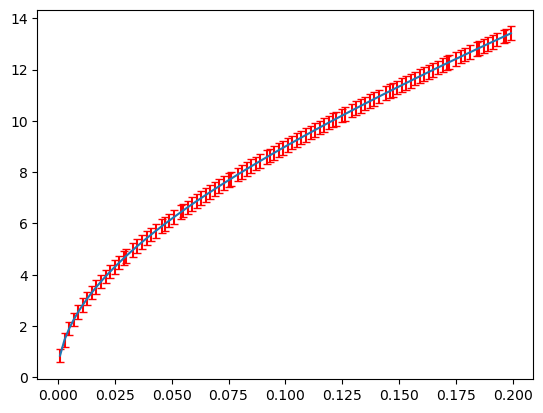

In [158]:
kittel_fit, kittel_popt, kittel_perr = py_loader.kittel_fit()

fig, ax = plt.subplots()

# ax.plot(py_loader.kittel_raw['B_field'].values, py_loader.kittel_raw['center'].values/1e9, 'o', label='Extracted Resonance Frequencies')
# ax.plot(py_loader.kittel_raw['B_field'].values, kittel_fit/1e9, label='Kittel Fit', linestyle='dashed')

# ax.errorbar(py_loader.kittel_raw['B_field'].values, py_loader.kittel_raw['center'].values/1e9, yerr=py_loader.kittel_raw['center_error'].values/1e9, fmt="None" ,capsize=4, label='Extracted Resonance Frequencies with Error Bars')
ax.errorbar(py_loader.kittel_raw['B_field'].values, kittel_fit/1e9, yerr=kittel_perr[0]/1e9, fmt='-',capsize = 3,ecolor = "red", label='Kittel Fit with Error Bars')

C:\Users\nicoe\AppData\Local\Temp\ipykernel_118436\1180807319.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


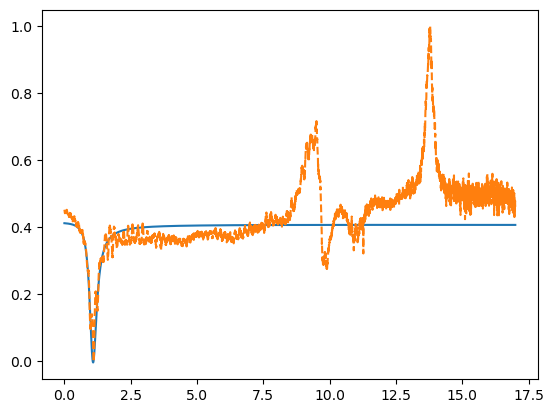

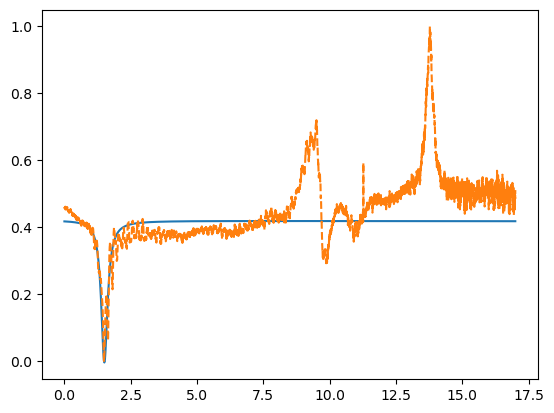

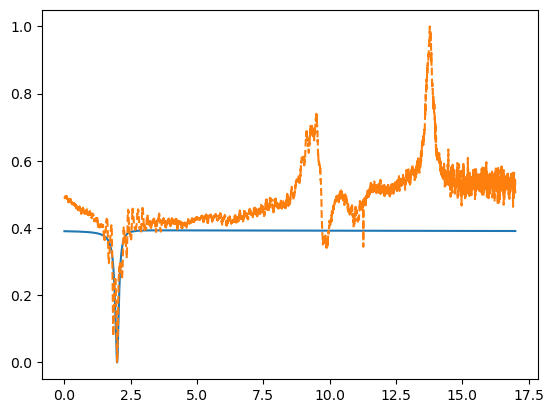

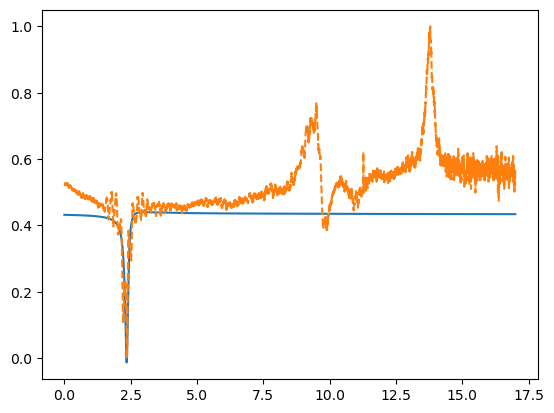

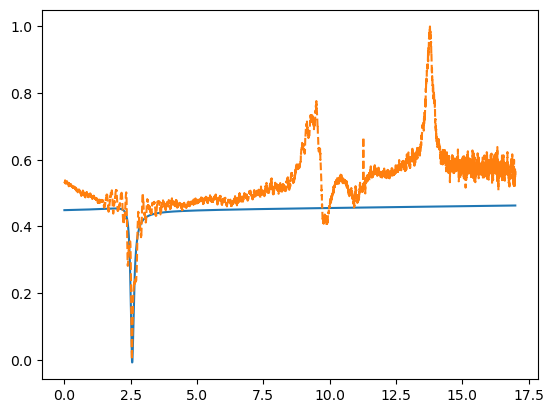

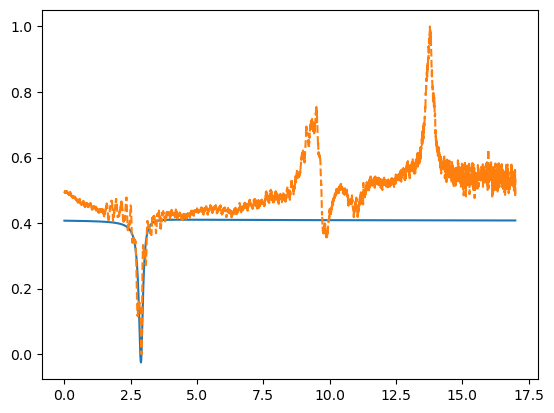

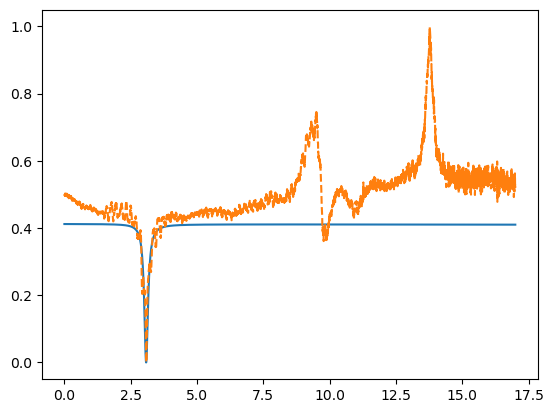

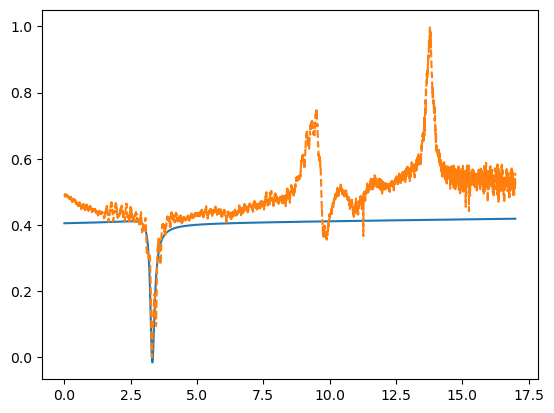

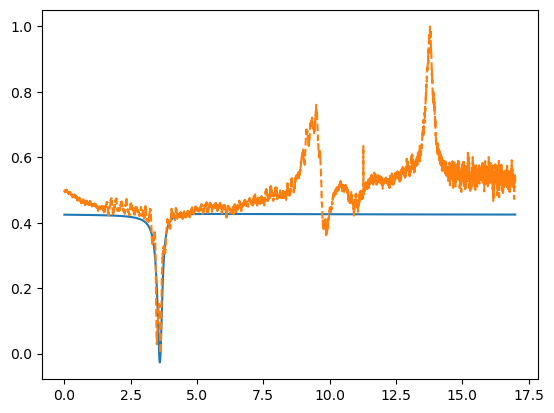

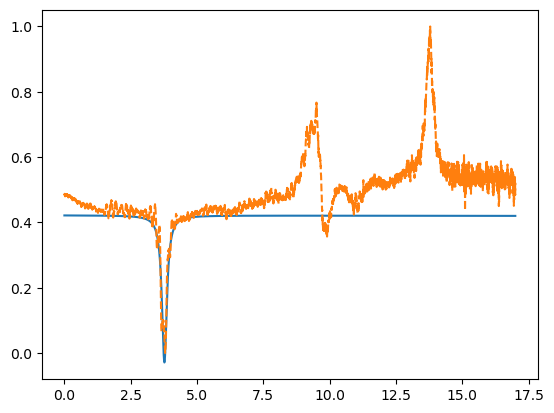

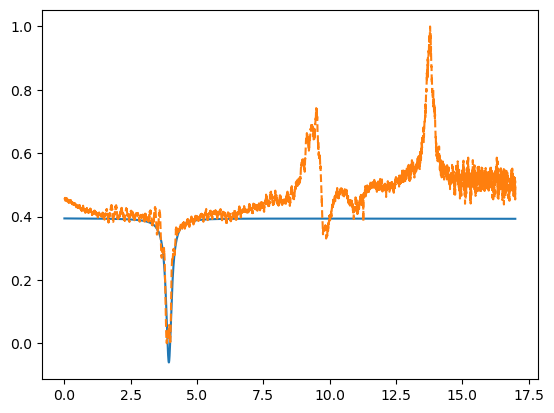

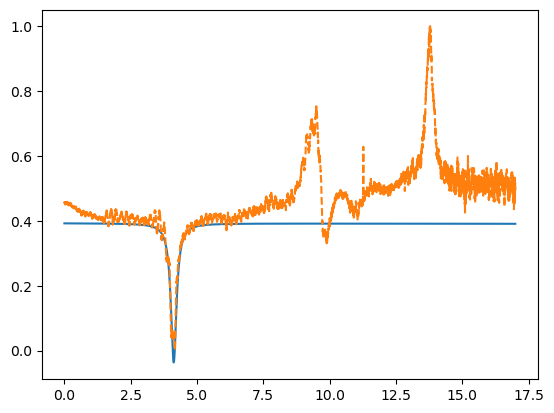

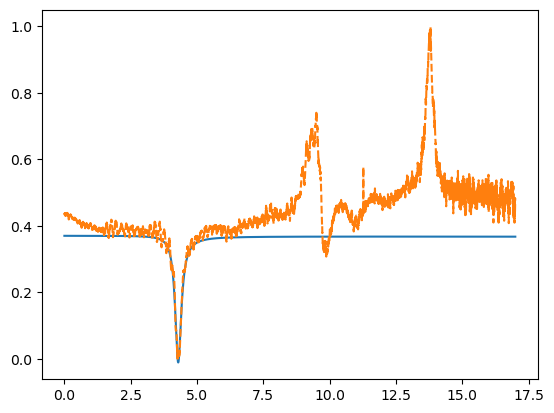

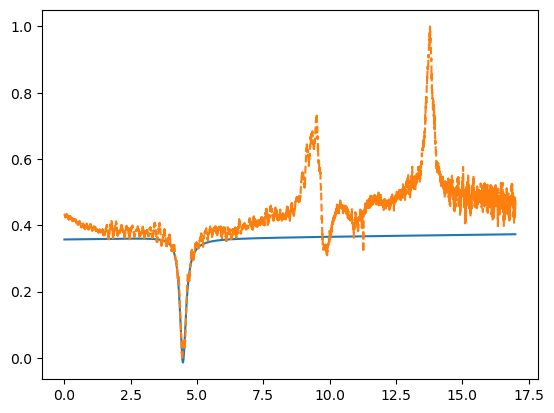

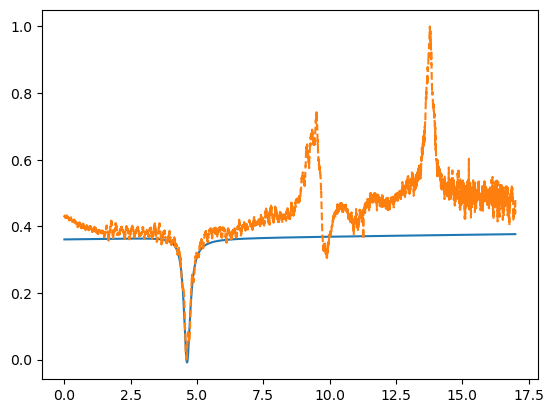

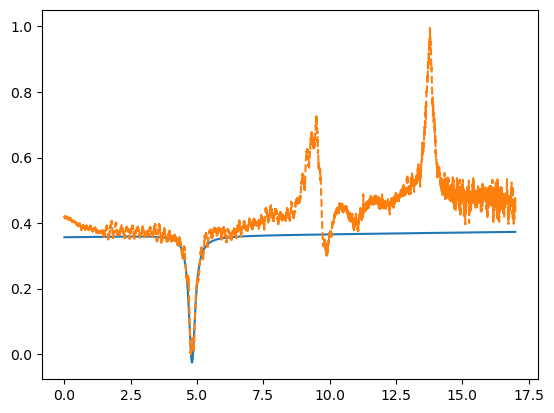

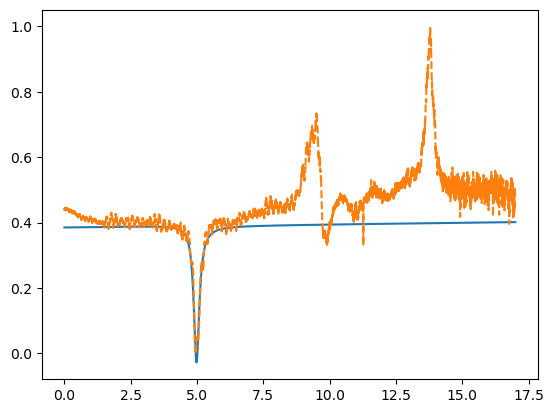

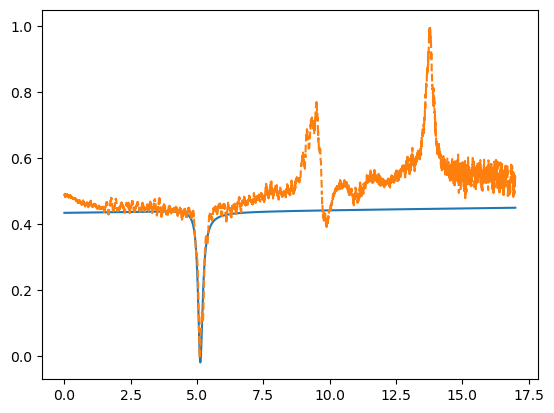

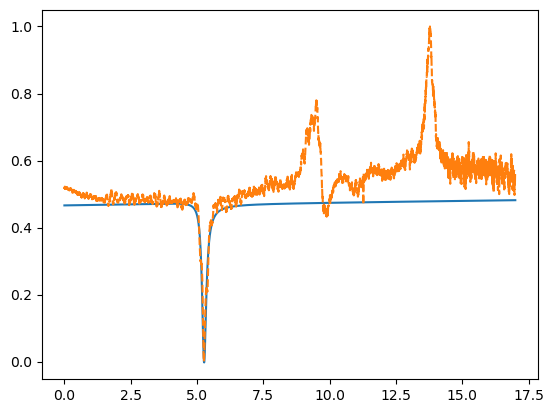

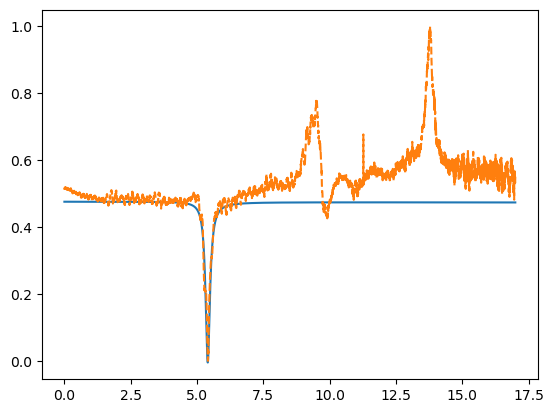

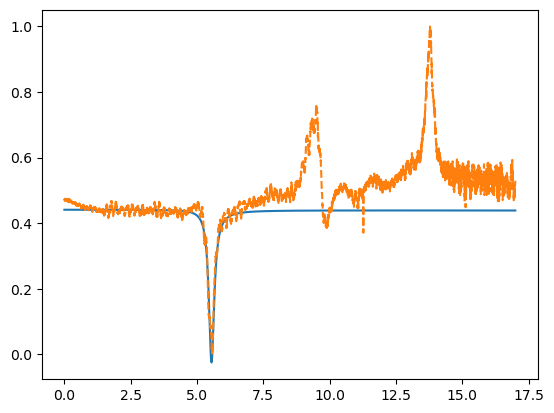

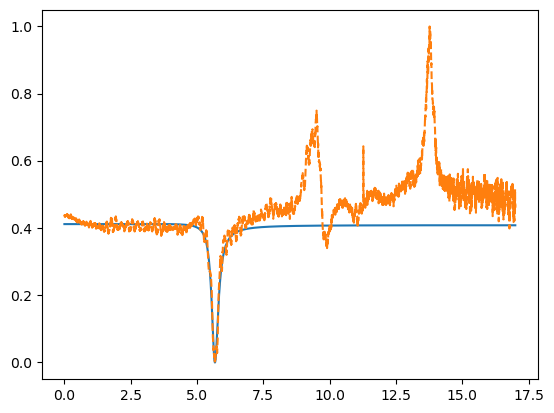

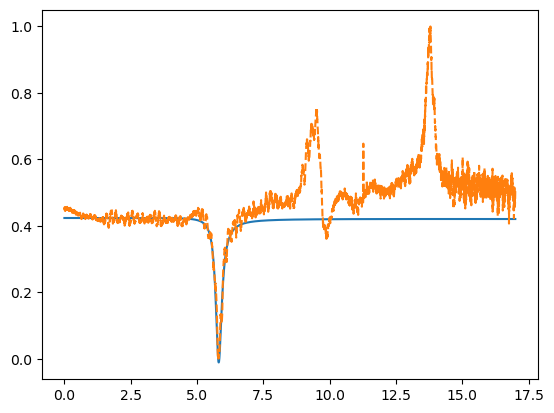

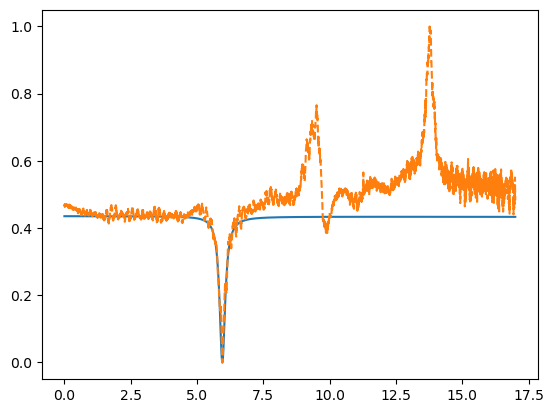

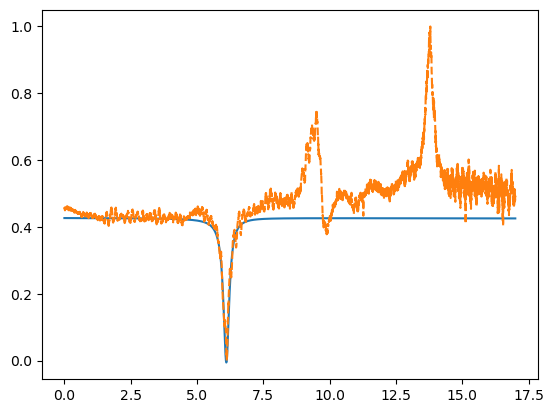

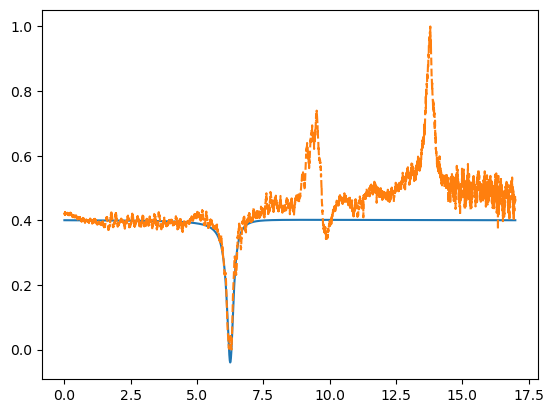

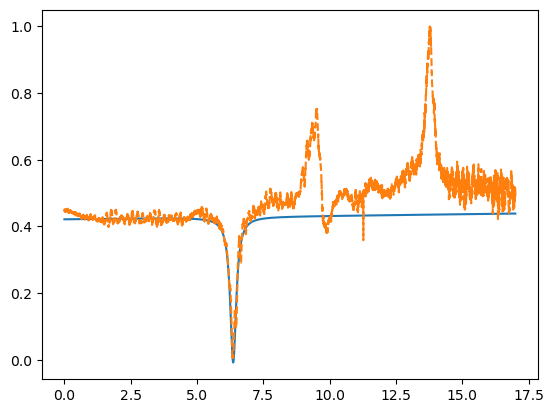

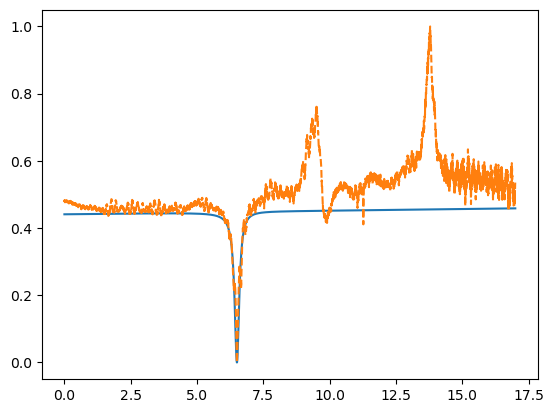

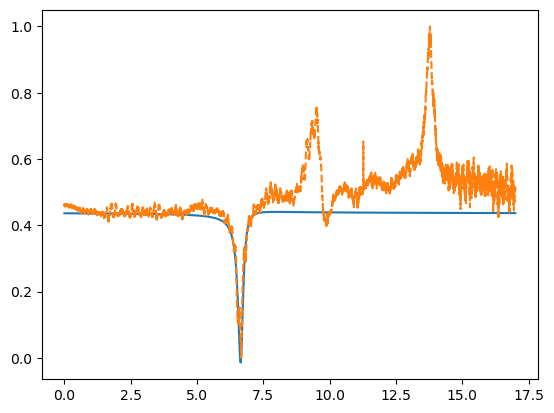

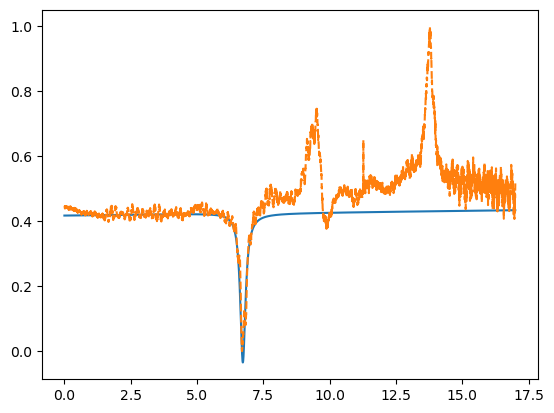

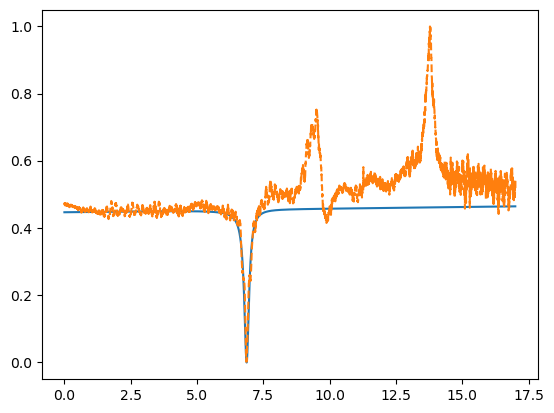

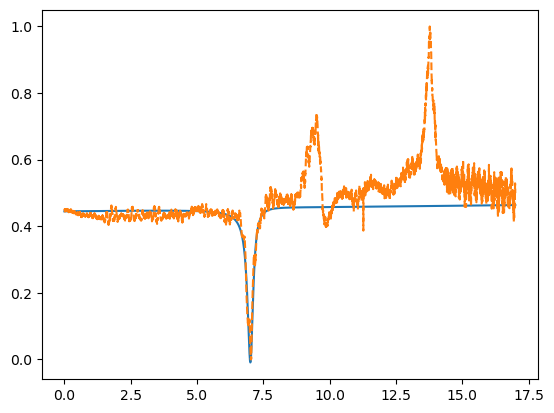

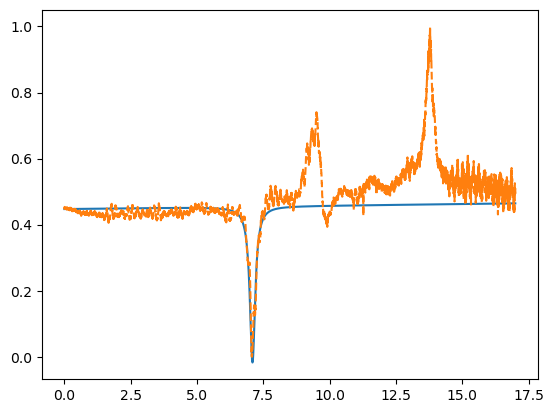

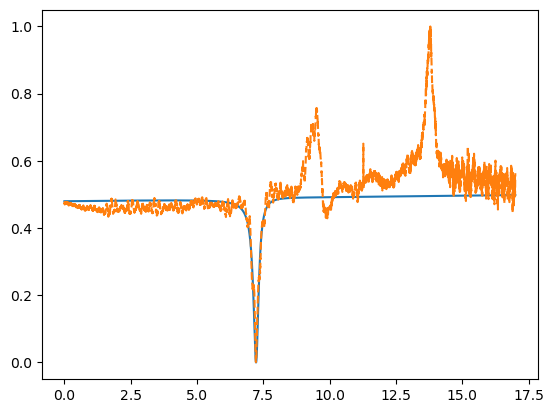

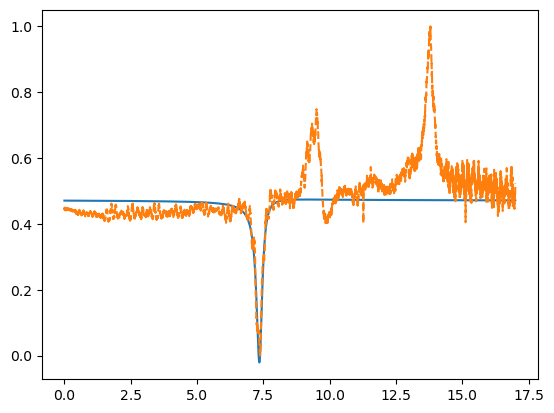

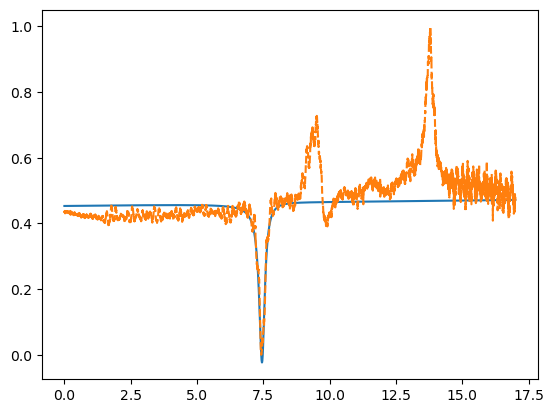

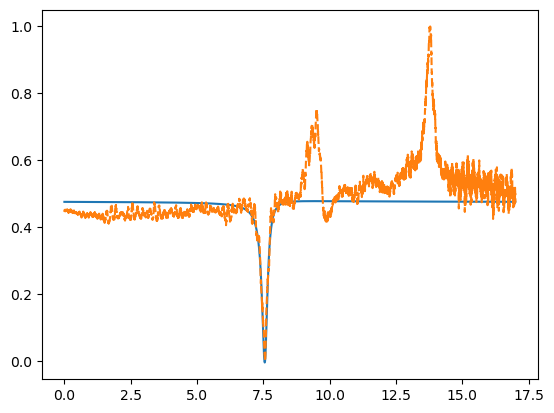

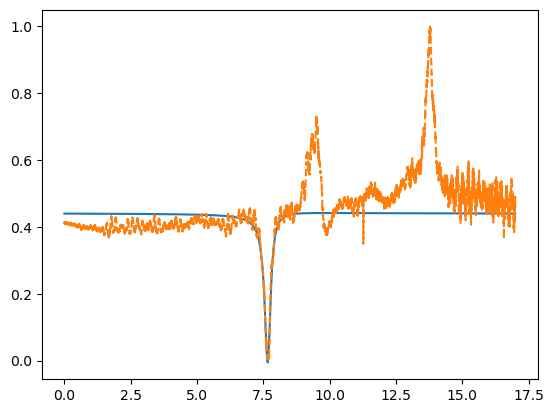

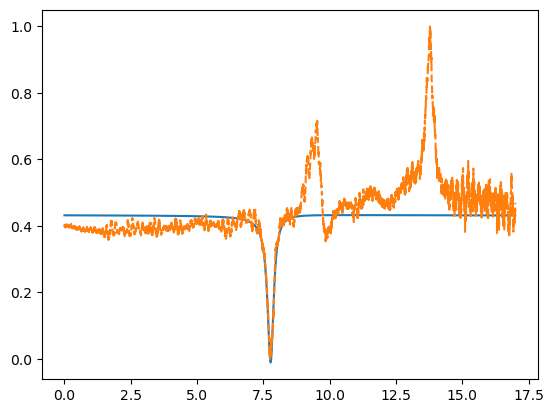

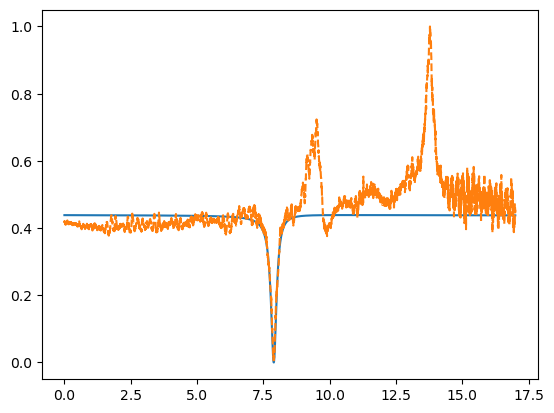

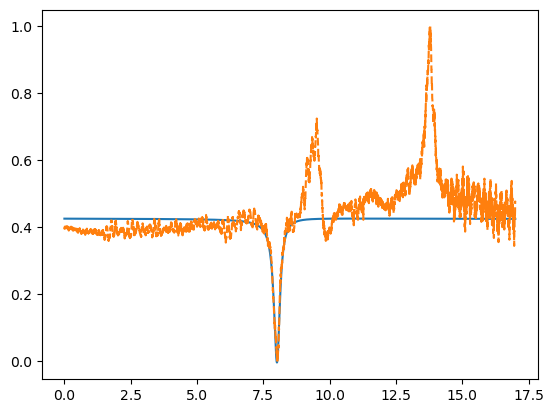

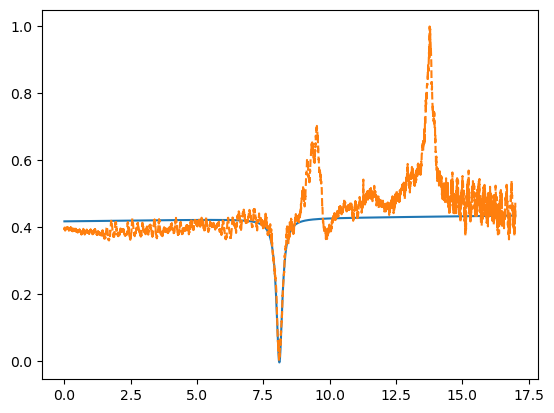

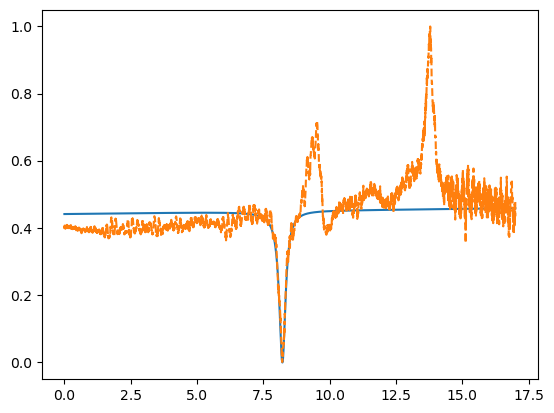

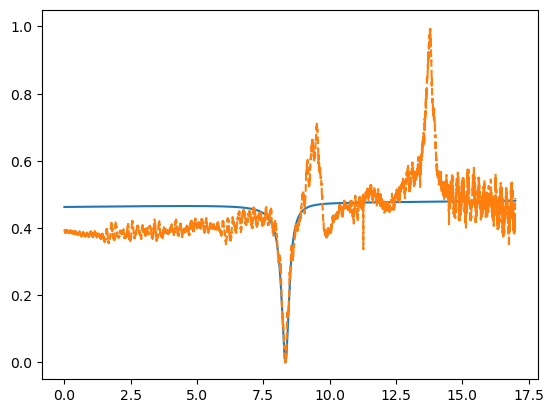

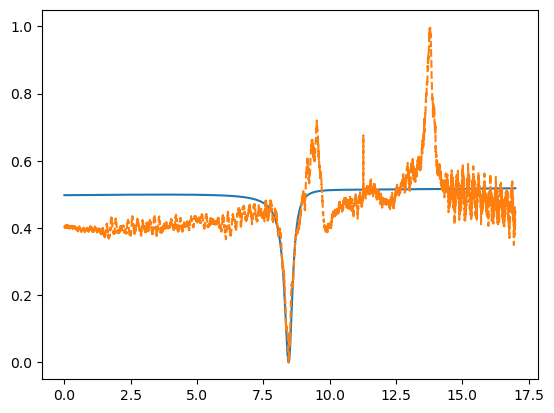

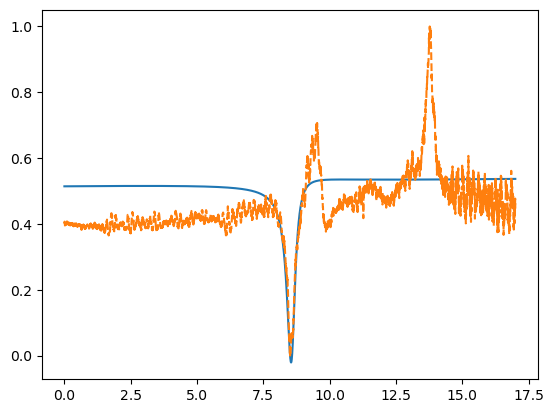

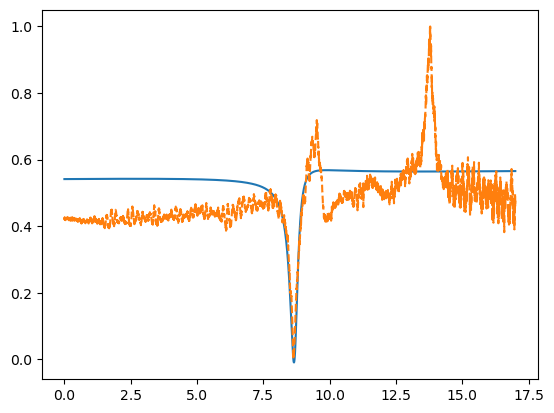

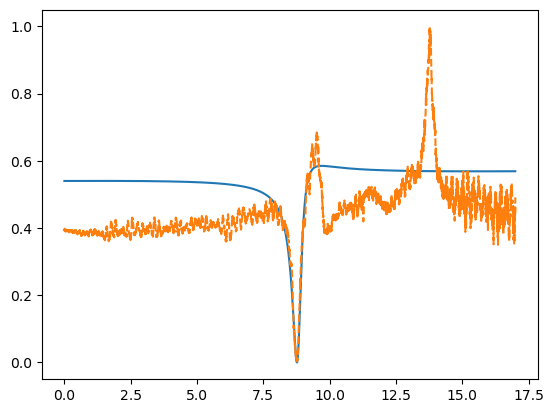

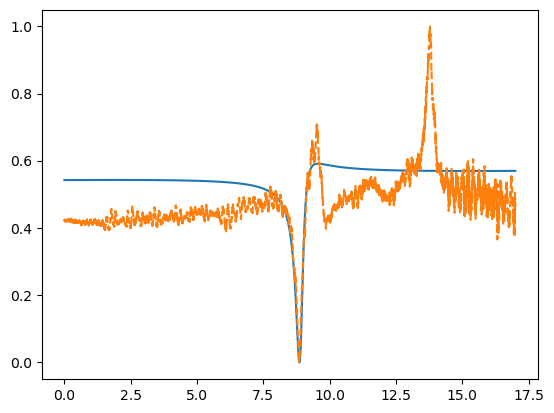

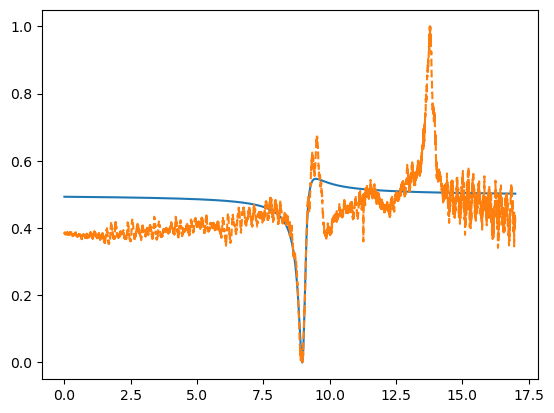

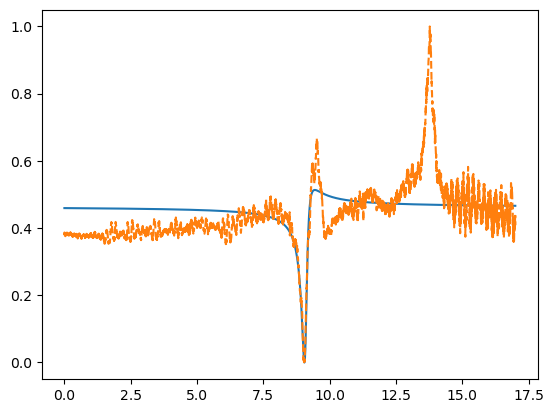

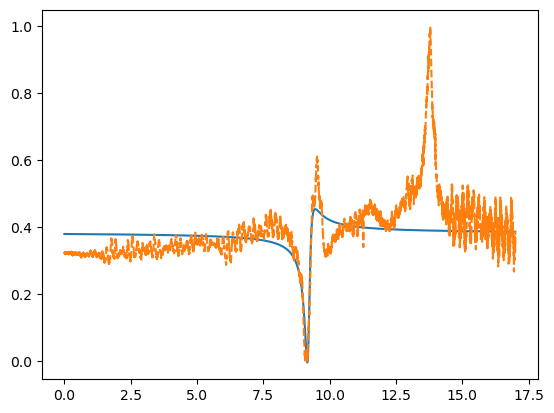

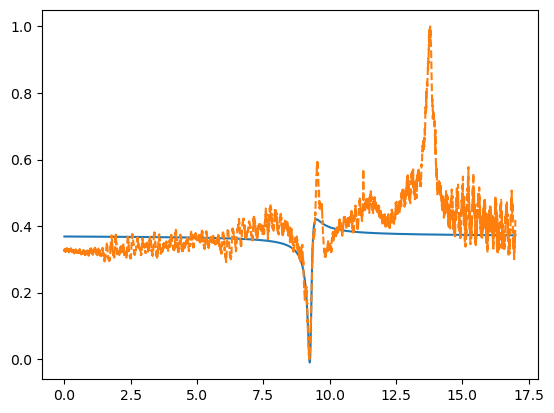

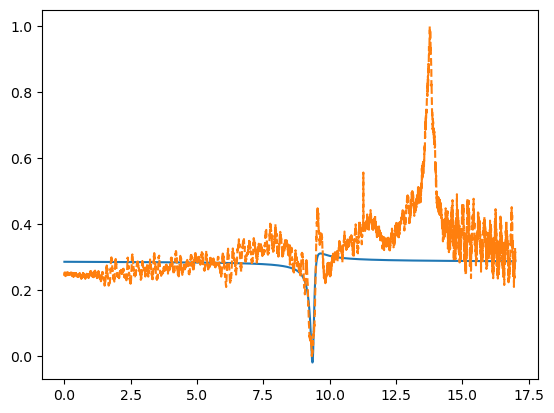

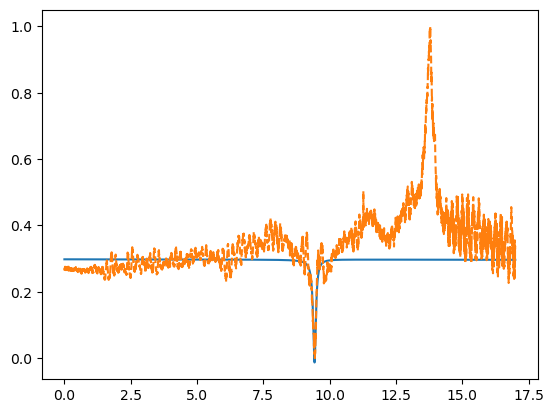

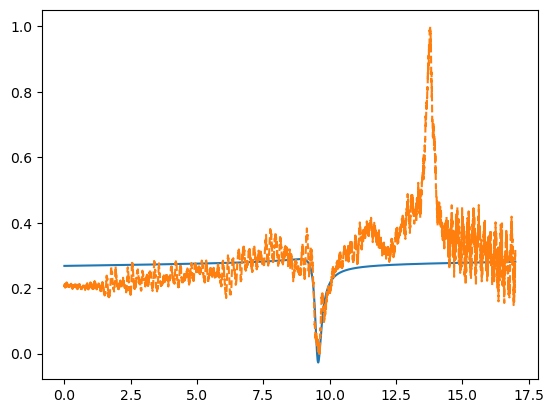

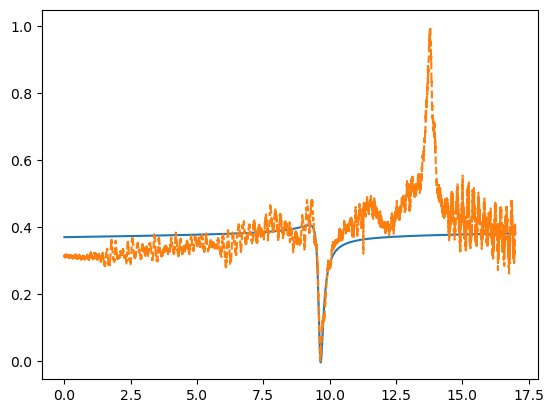

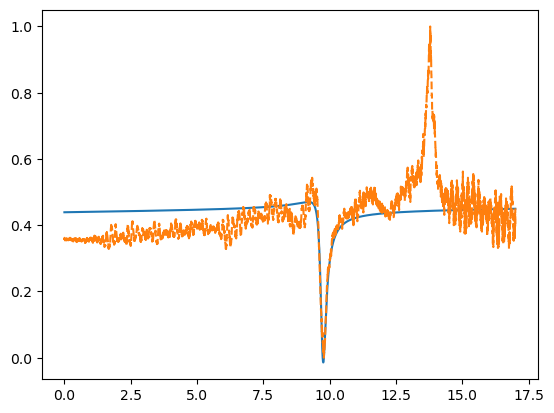

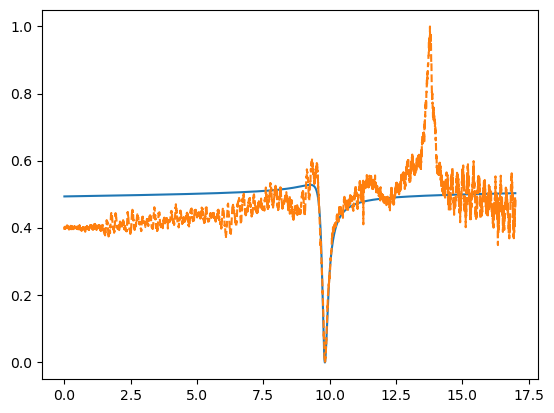

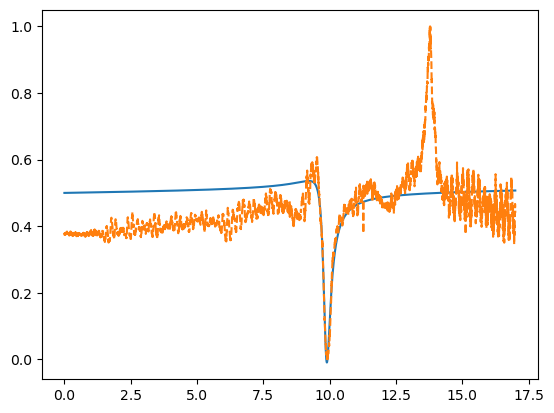

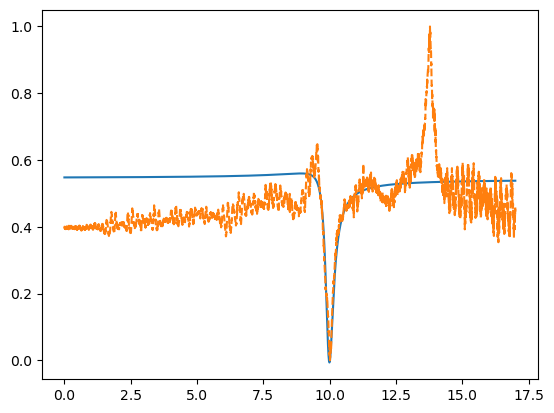

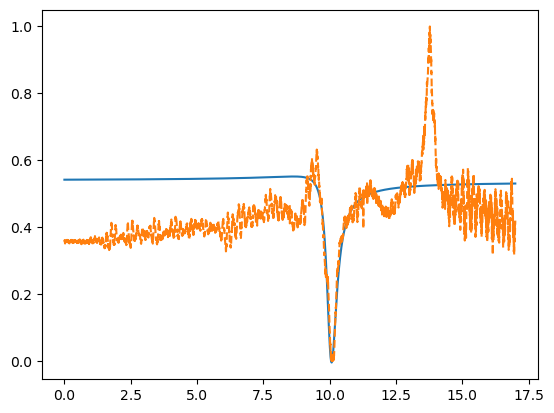

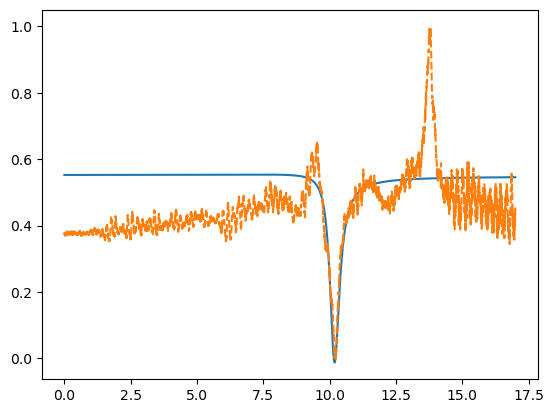

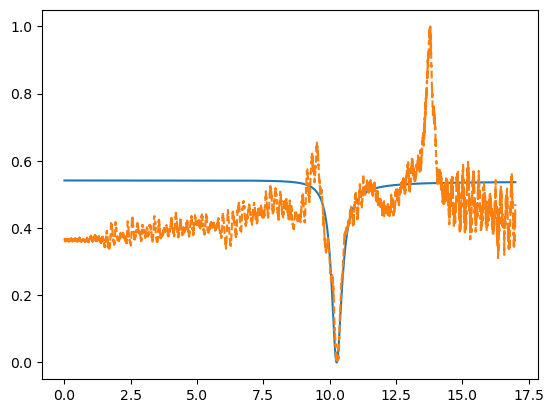

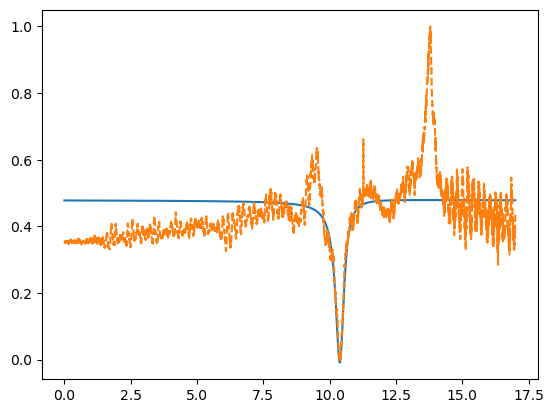

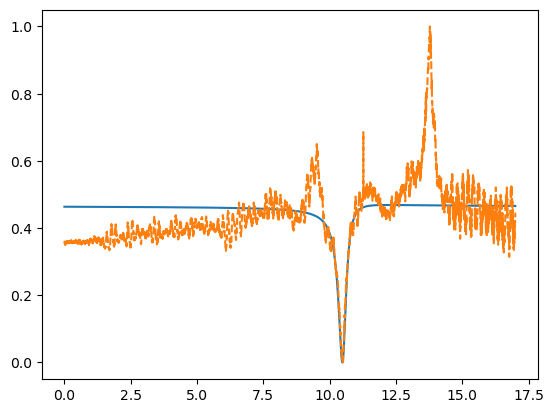

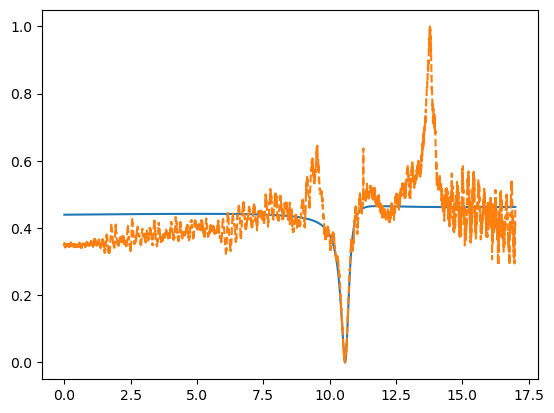

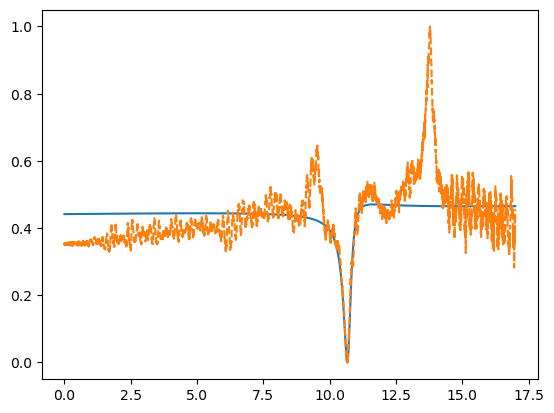

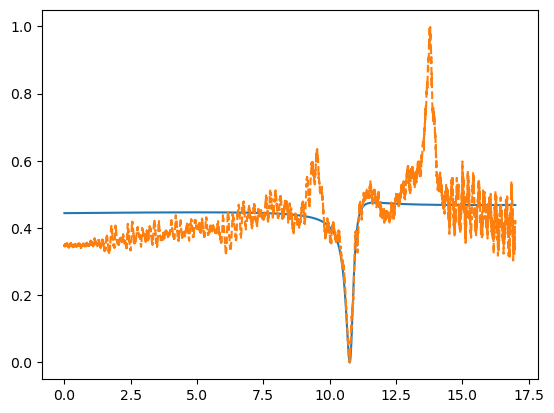

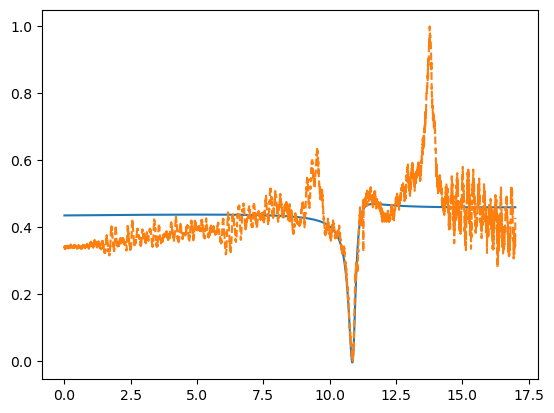

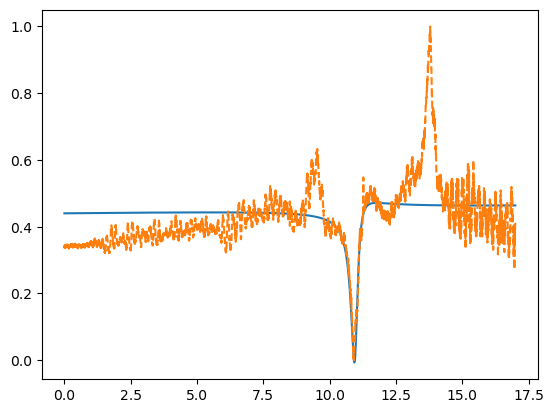

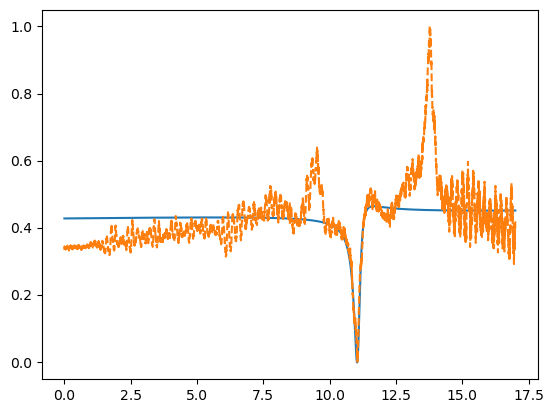

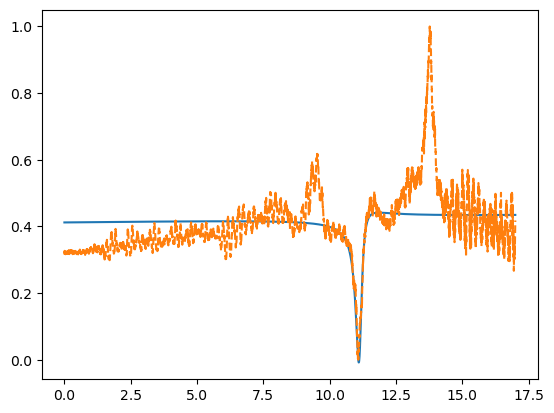

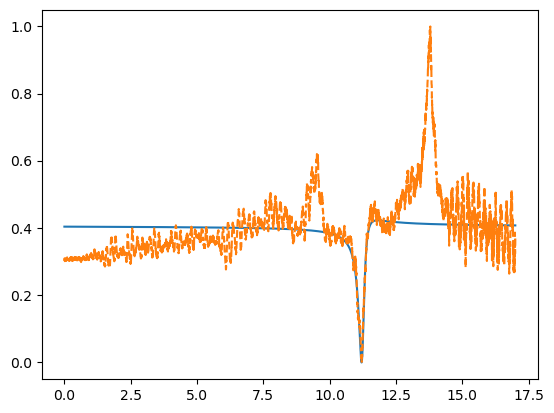

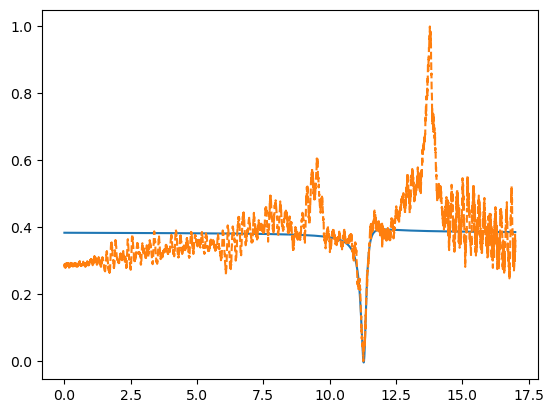

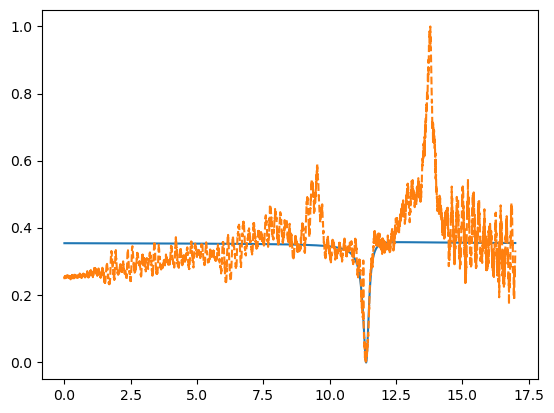

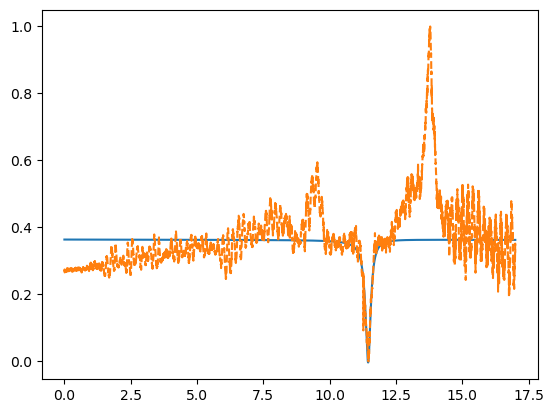

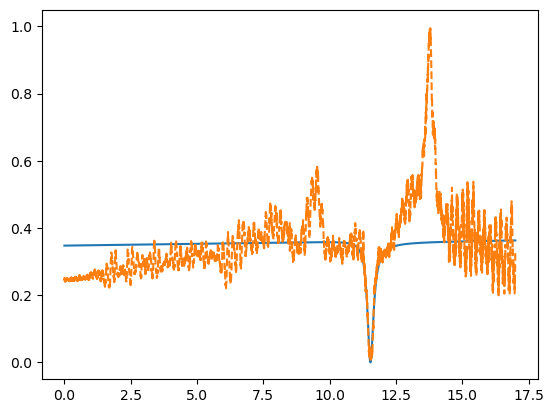

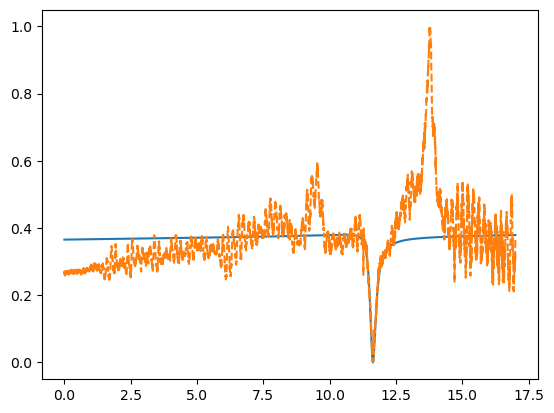

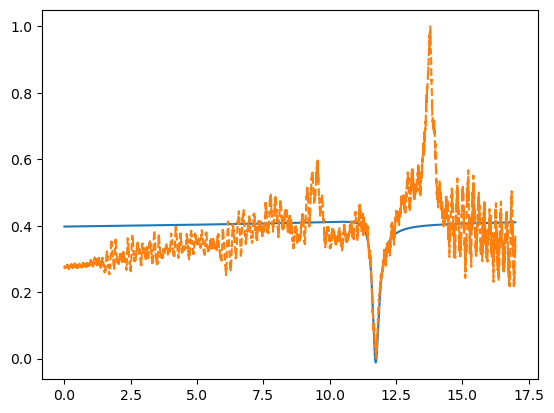

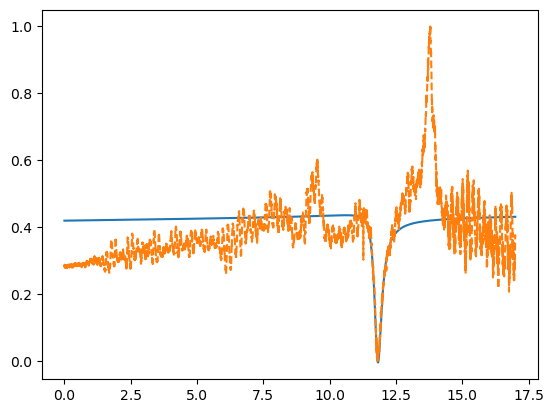

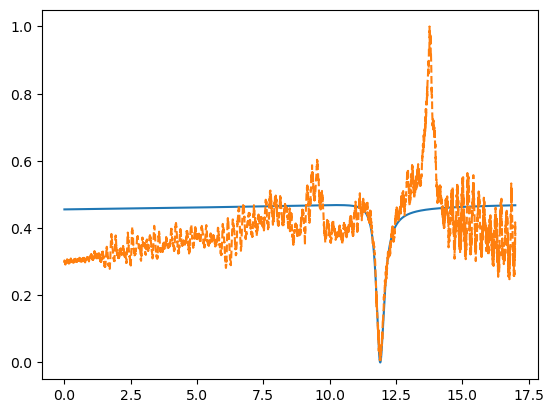

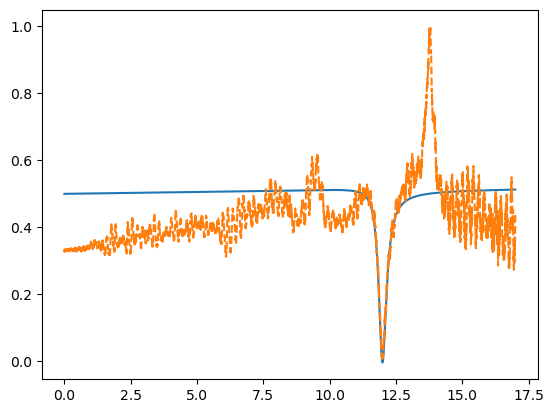

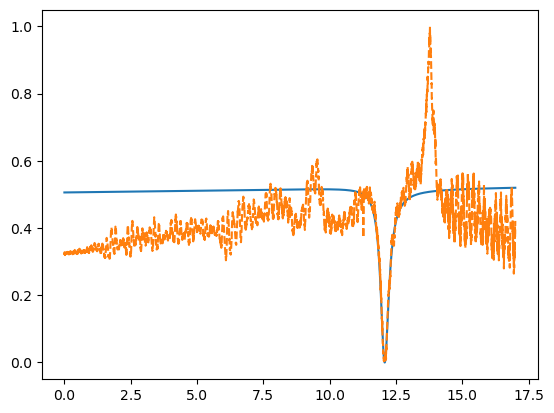

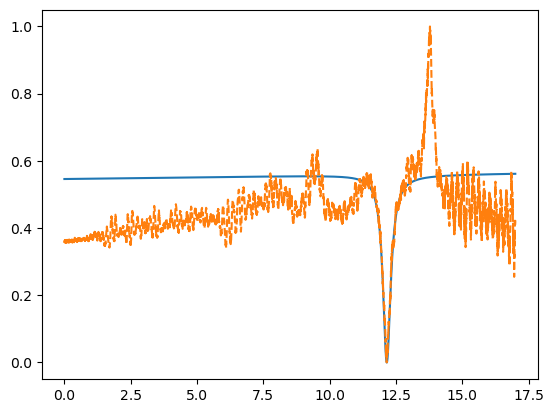

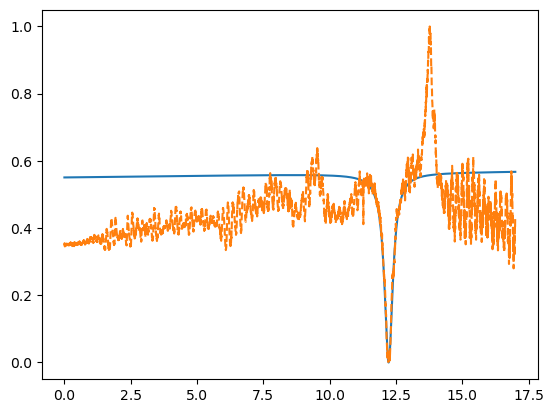

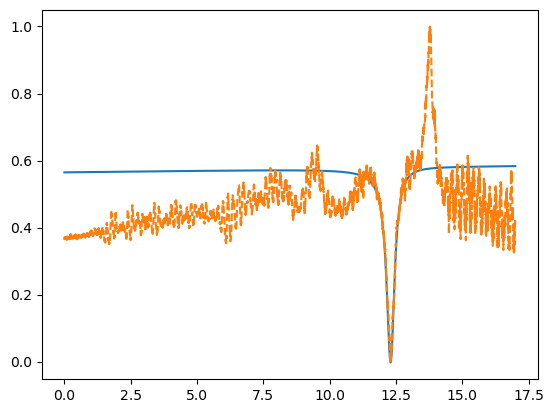

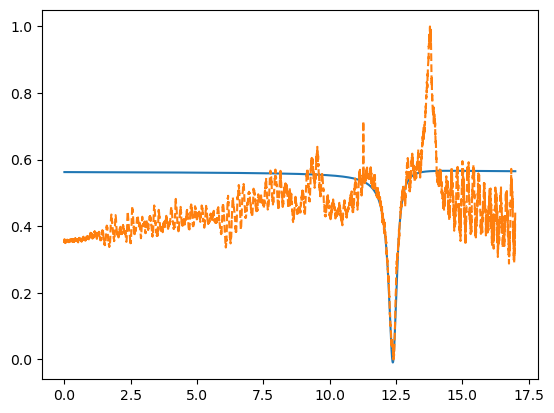

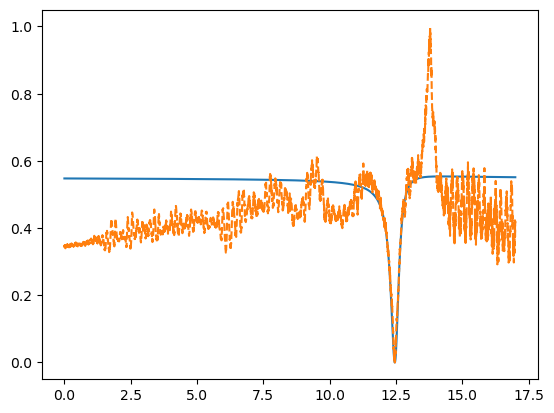

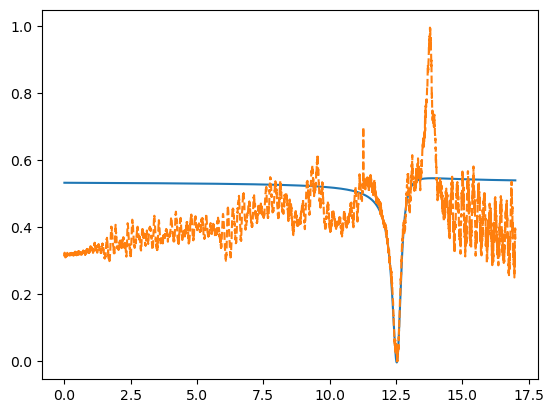

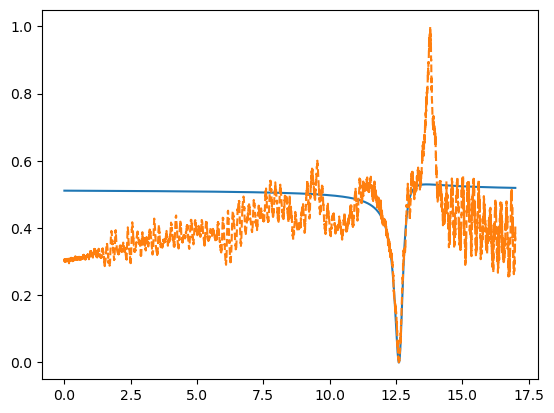

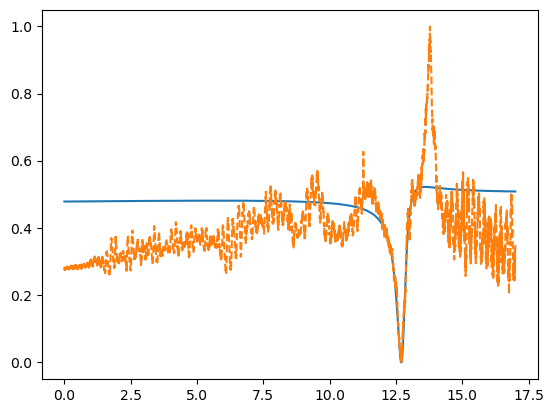

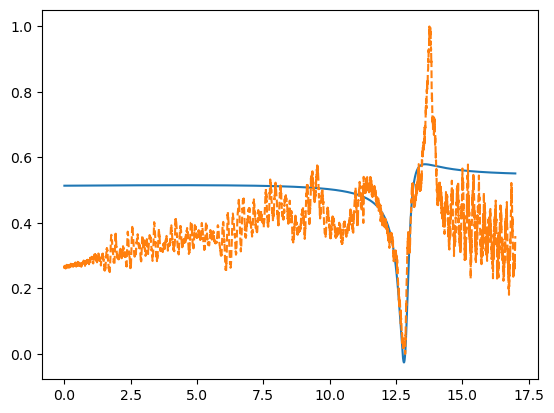

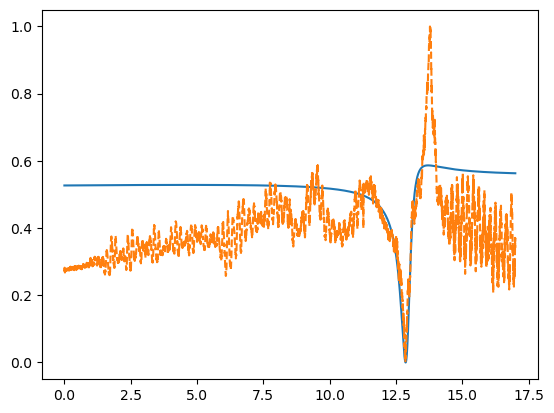

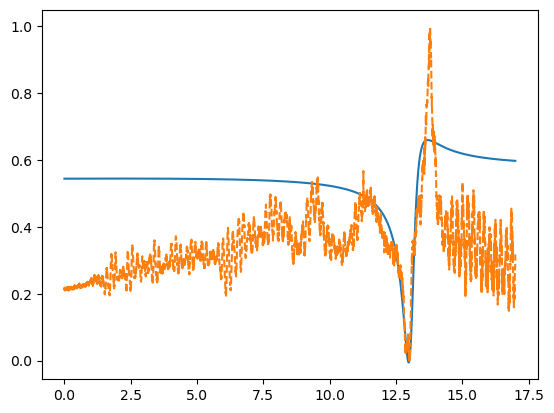

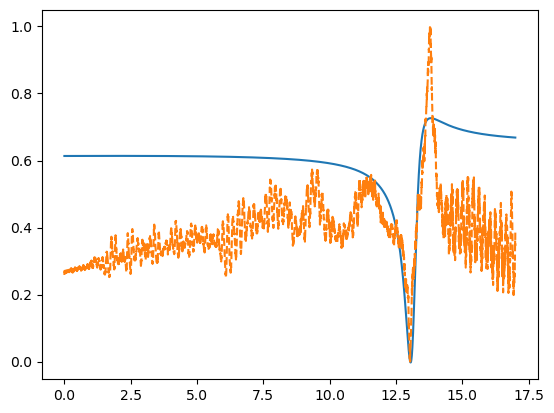

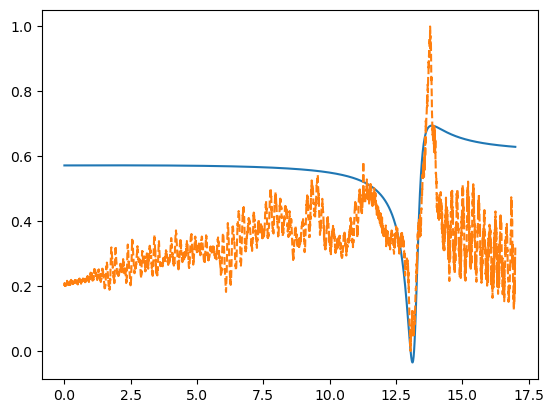

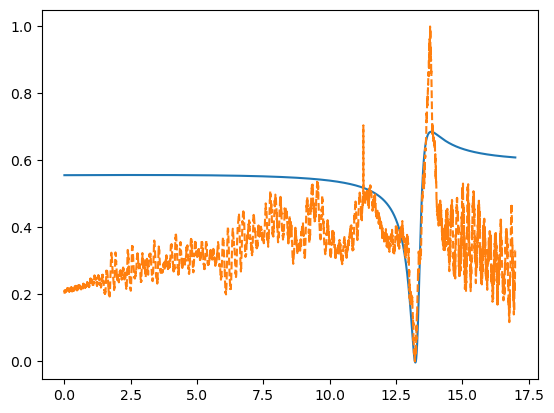

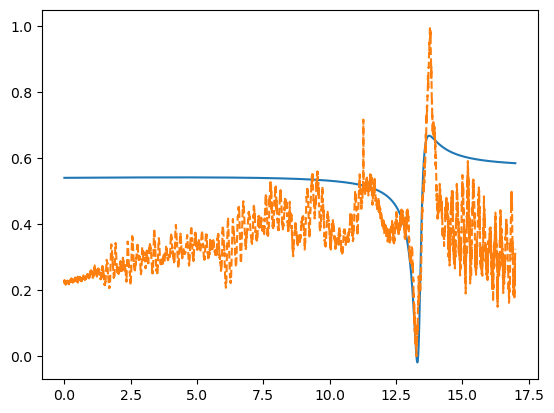

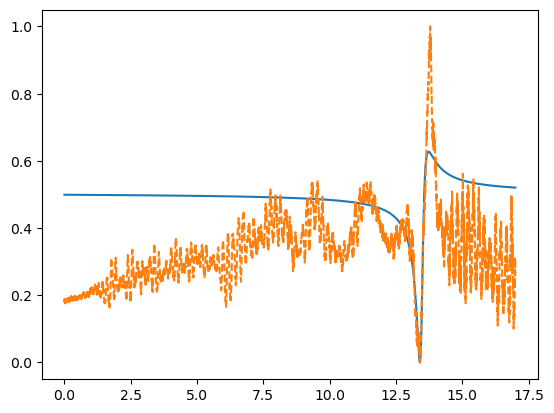

In [126]:

normalised_df = df.copy()

normalised_df = (normalised_df - normalised_df.min()) / (normalised_df.max() - normalised_df.min())

for column in df_lorentz_py.columns:
    fig, ax = plt.subplots()

    ax.plot(df_lorentz_py.index.values/1e9, df_lorentz_py[column].values, label=f"B={column:.2f} mT")
    ax.plot(normalised_df.index.values/1e9, normalised_df[column].values, label=f"Data B={column:.2f} mT", linestyle='dashed')

C:\Users\nicoe\AppData\Local\Temp\ipykernel_118436\1301222247.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


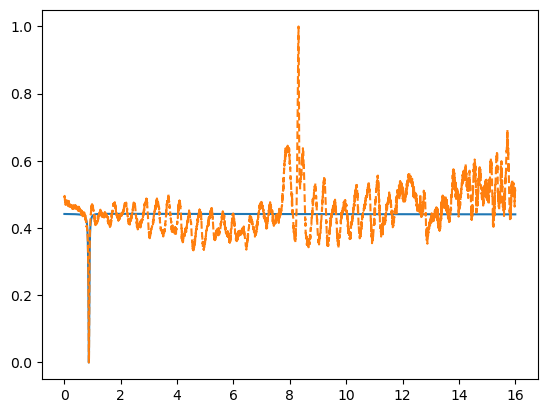

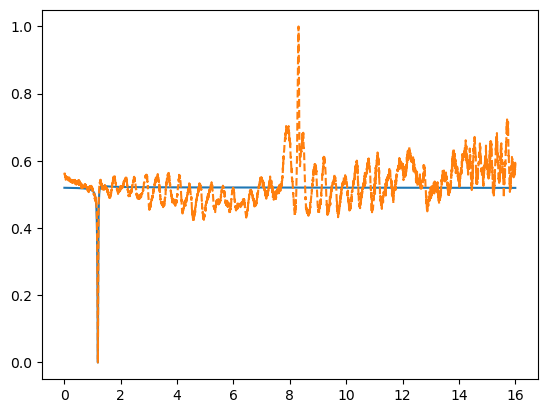

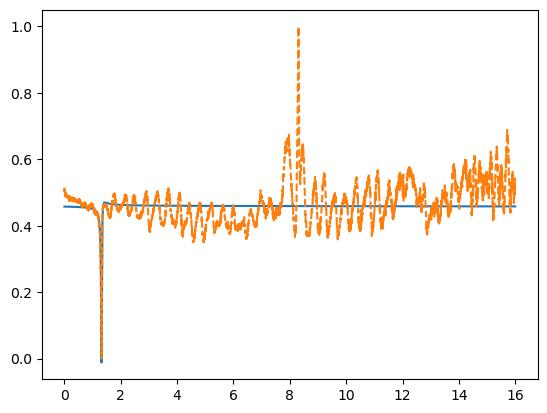

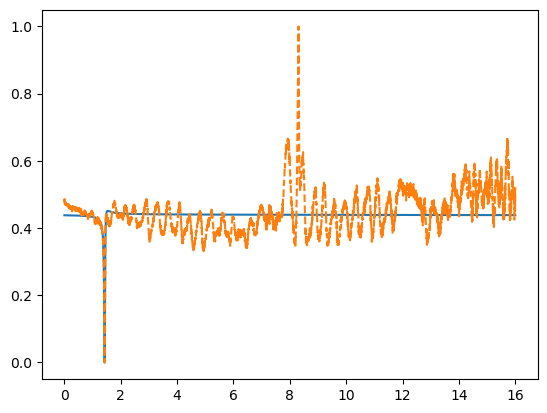

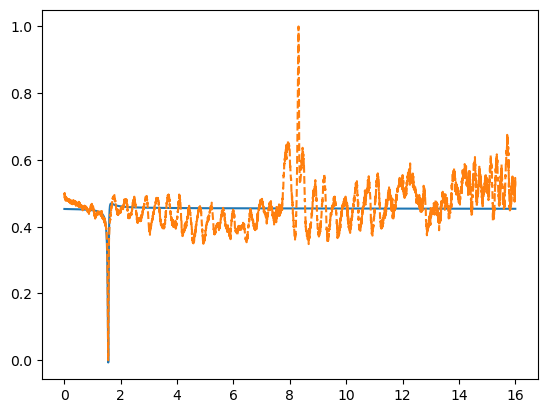

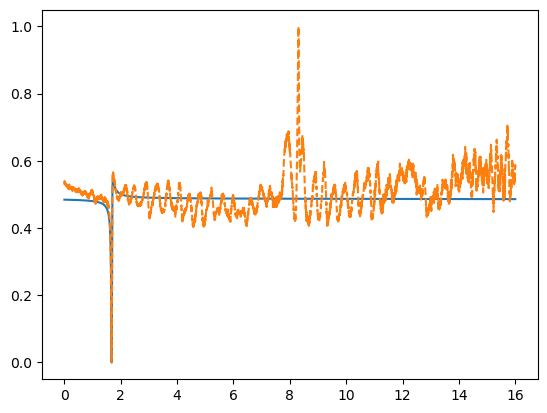

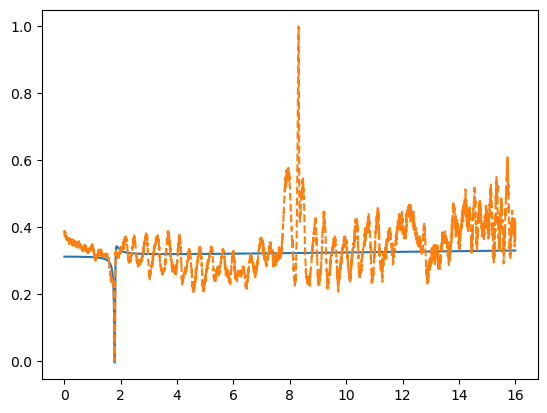

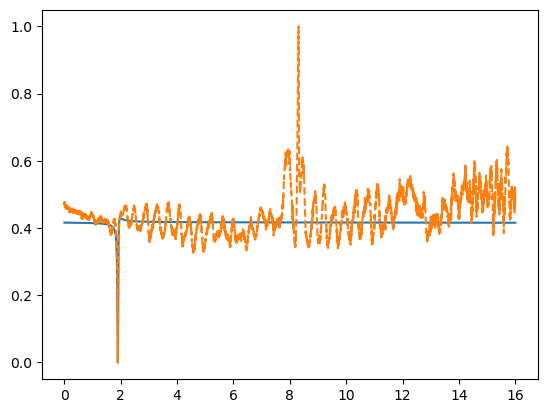

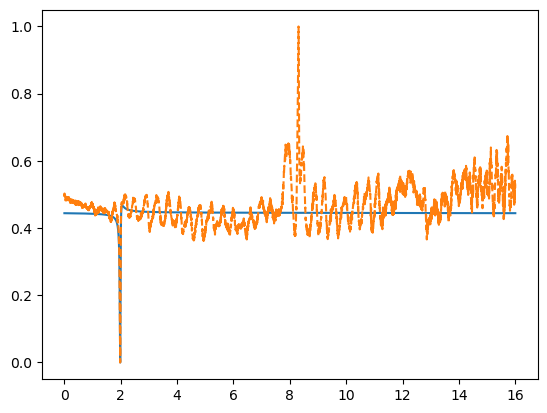

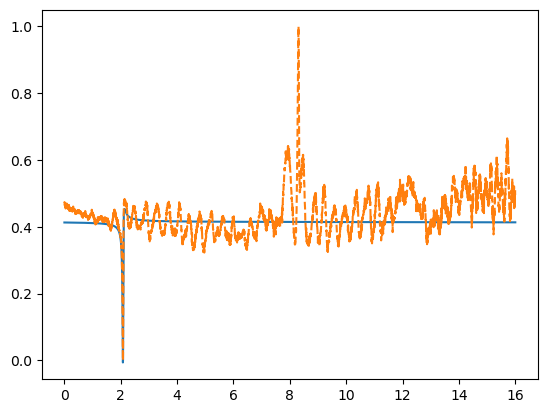

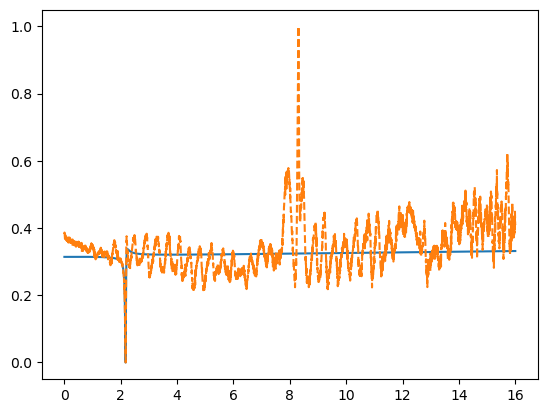

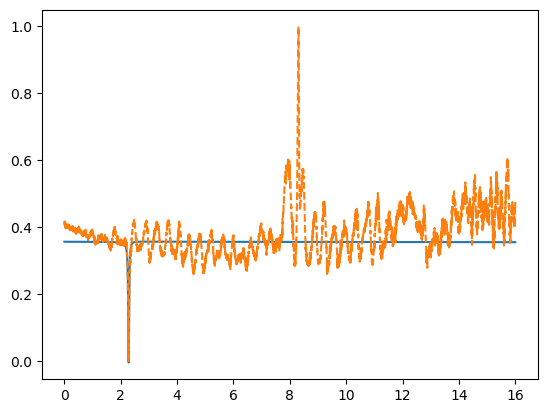

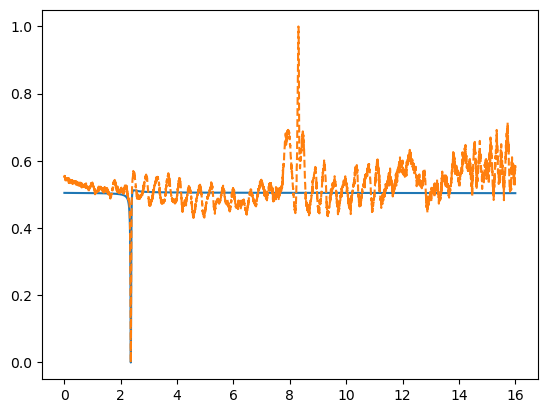

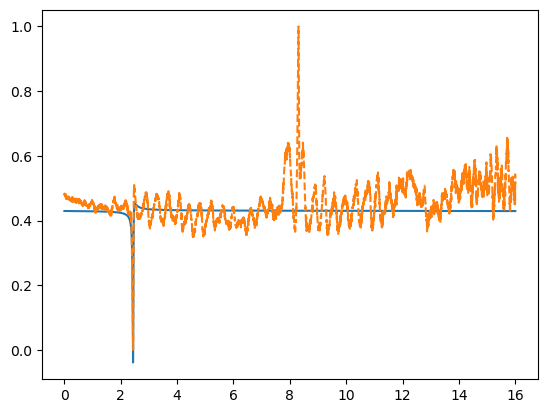

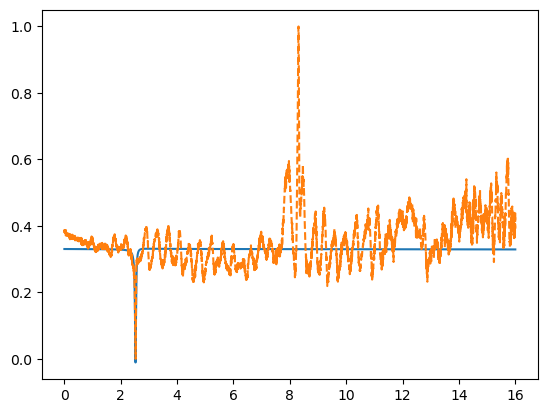

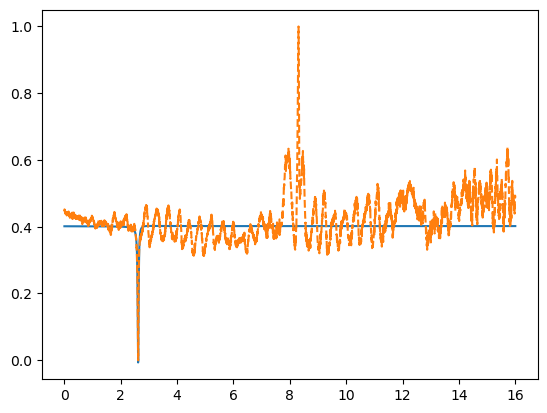

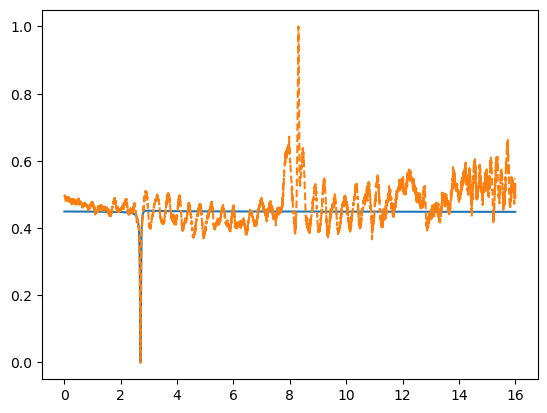

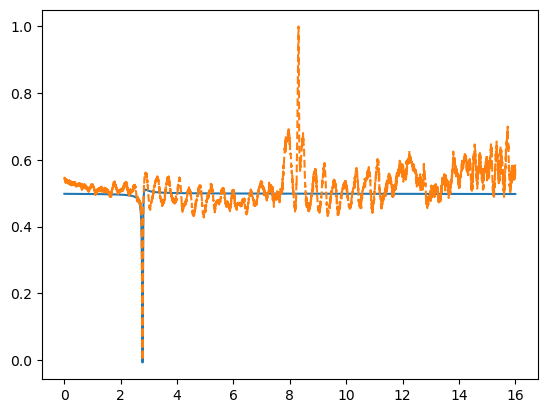

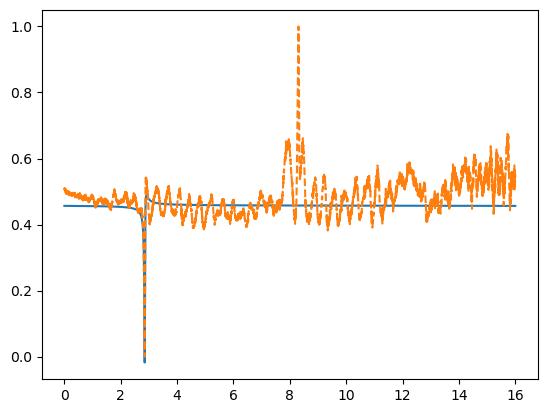

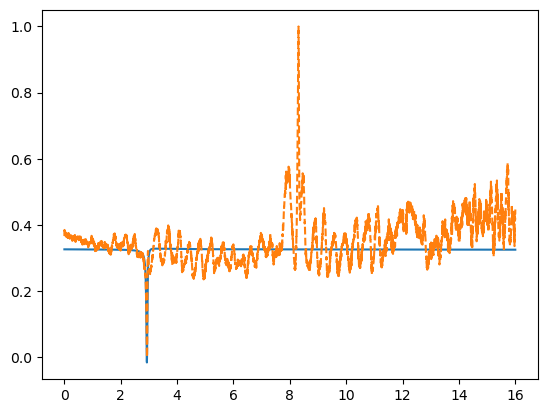

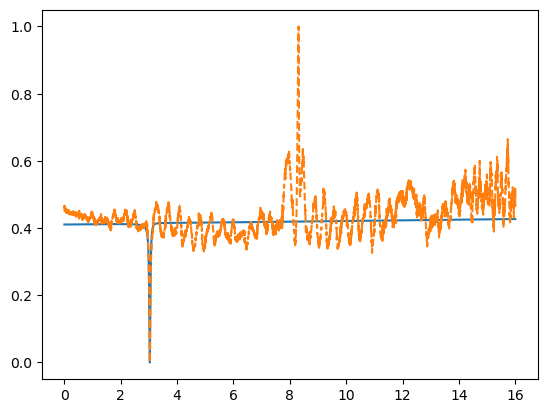

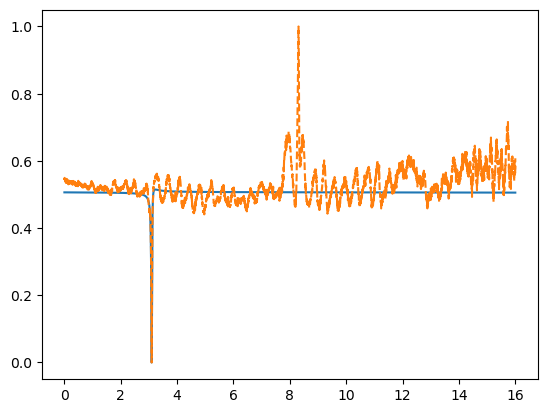

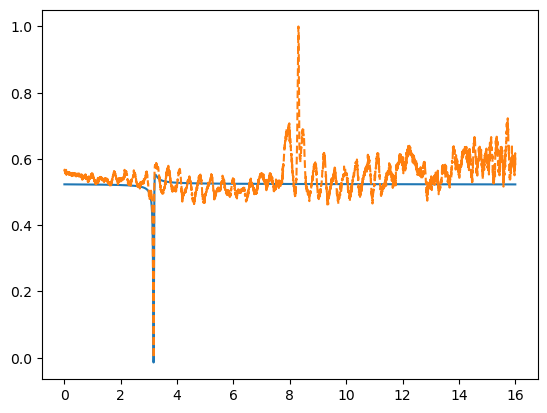

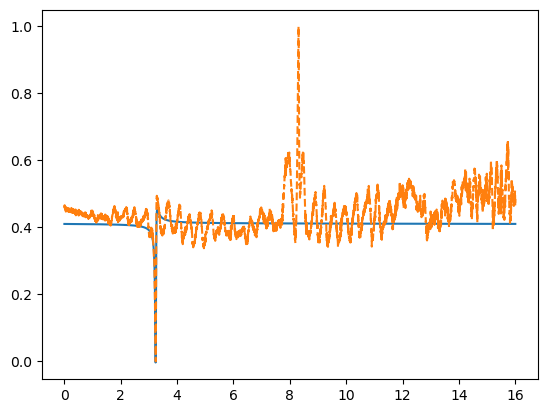

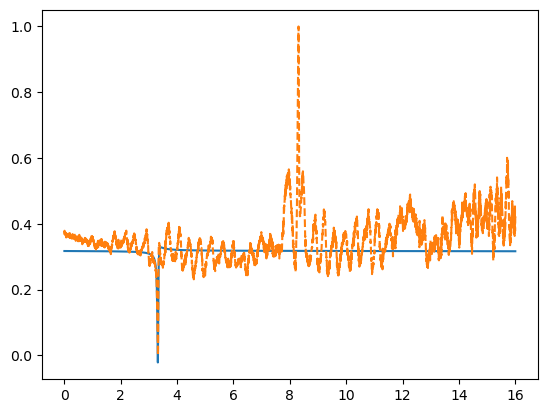

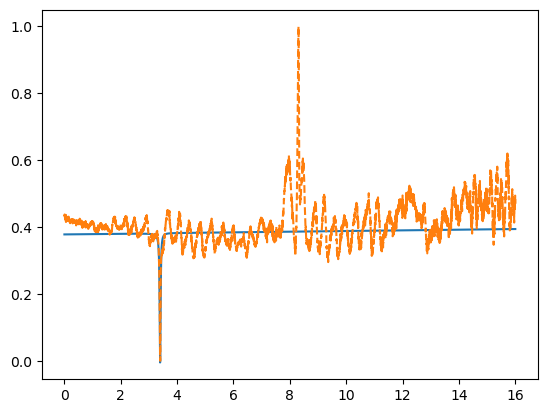

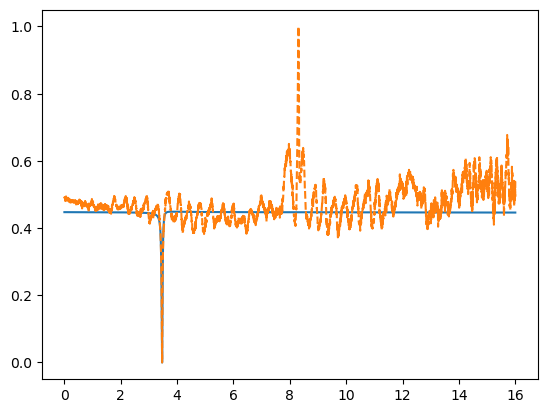

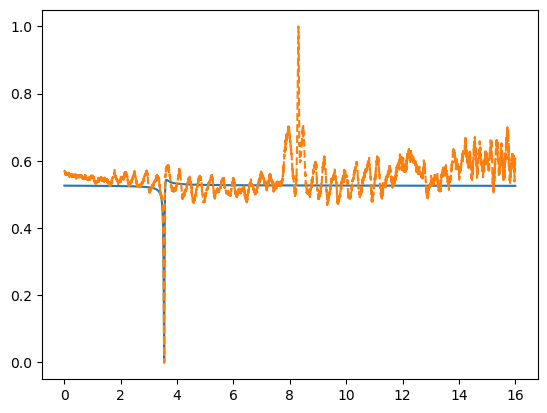

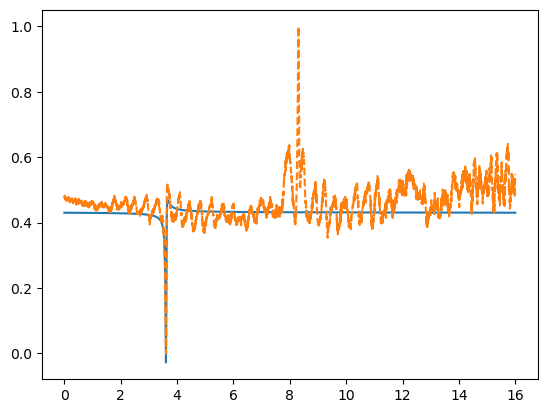

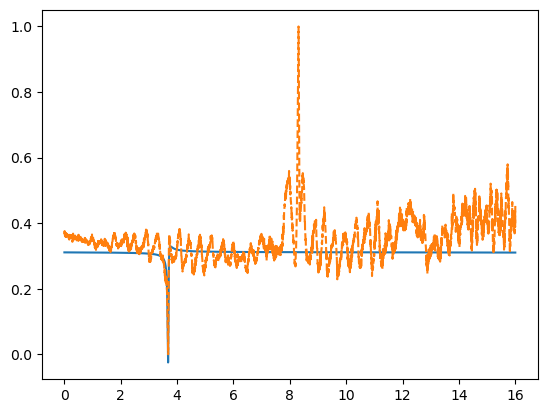

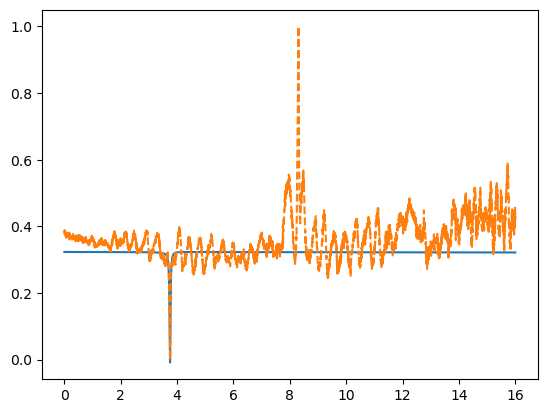

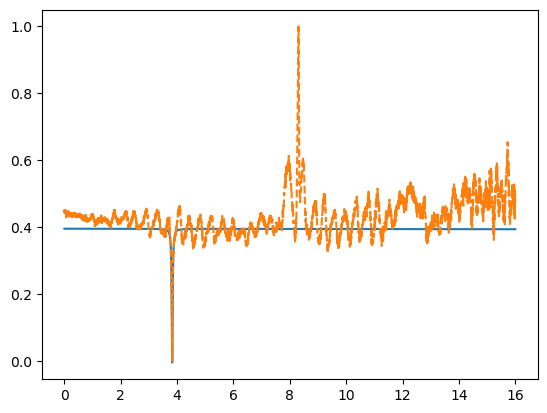

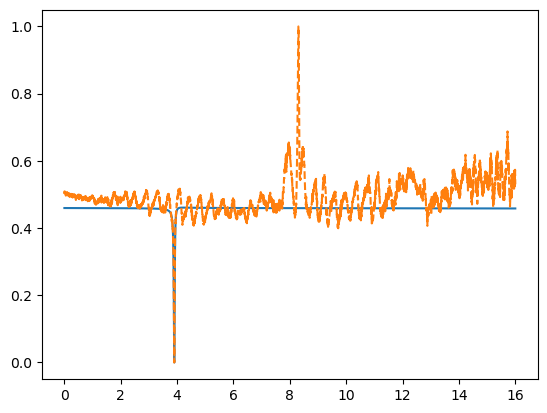

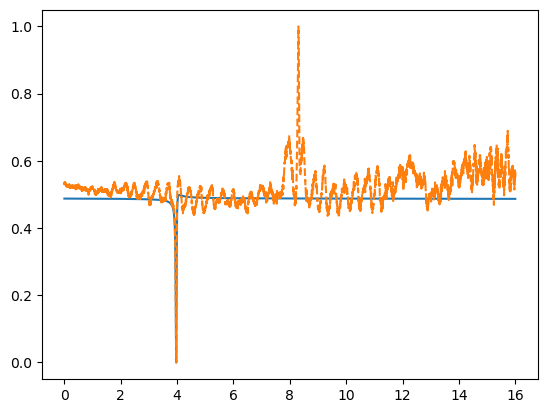

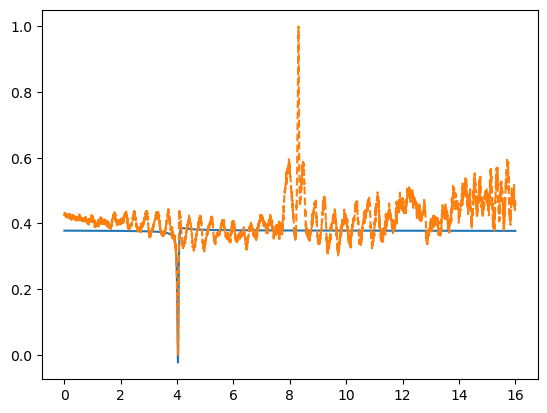

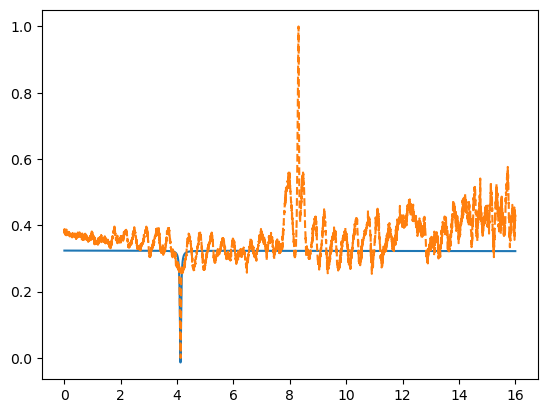

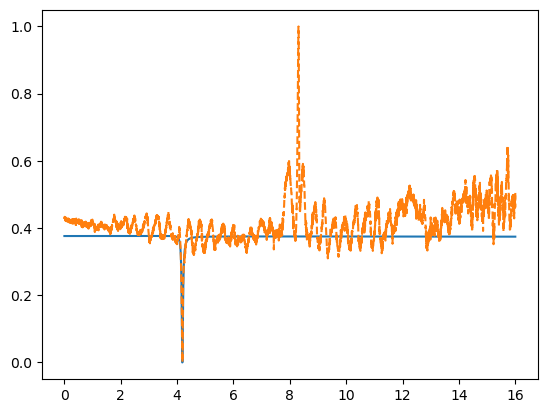

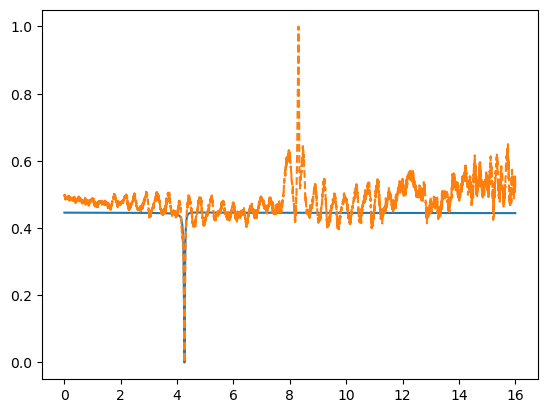

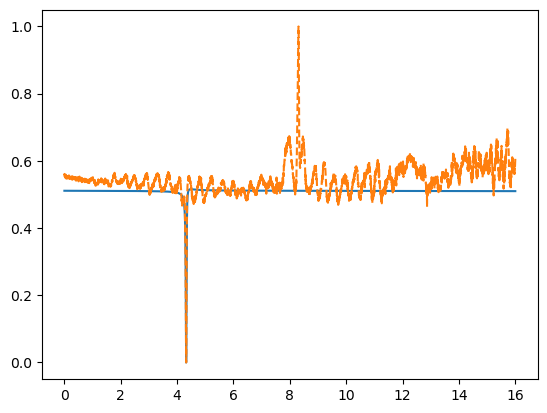

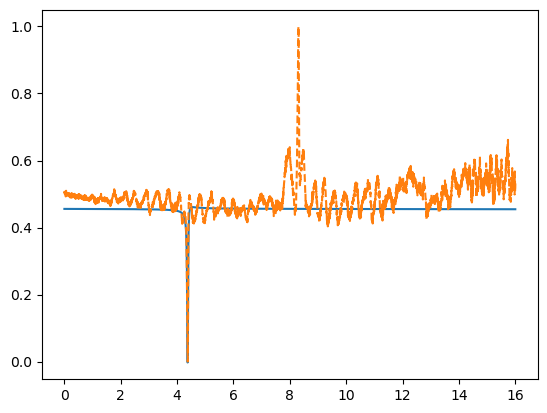

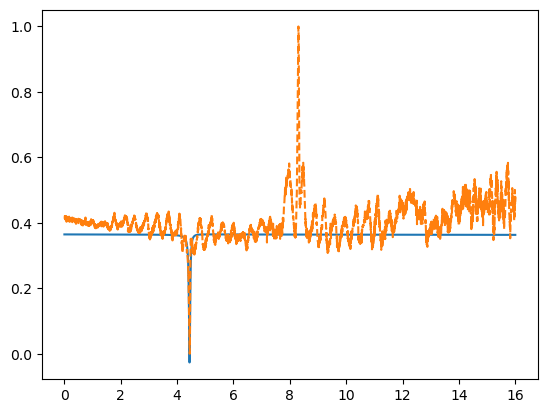

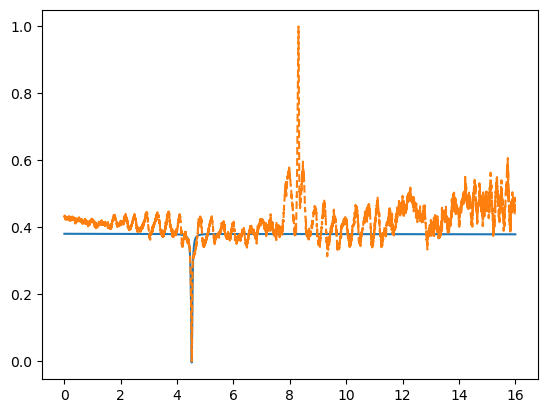

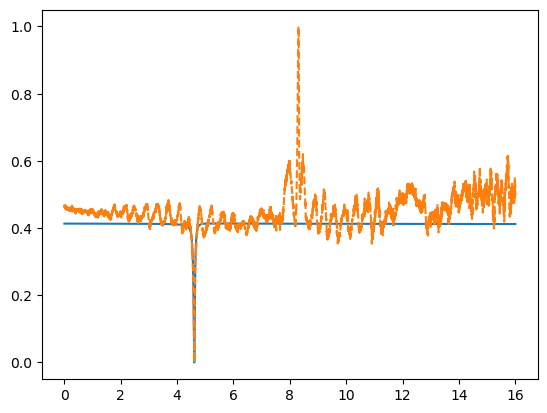

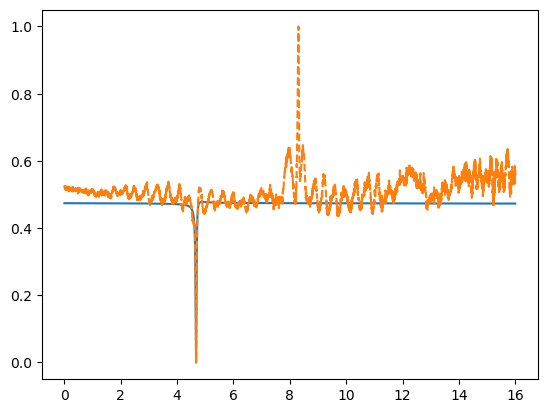

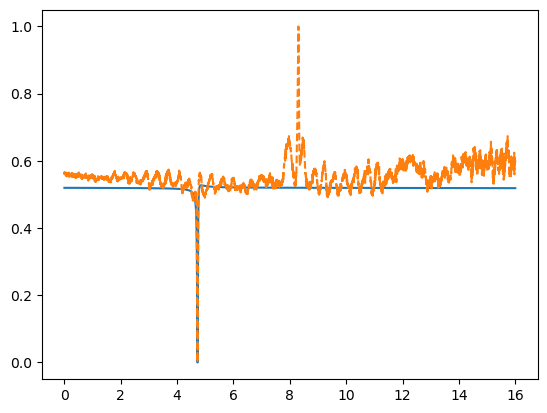

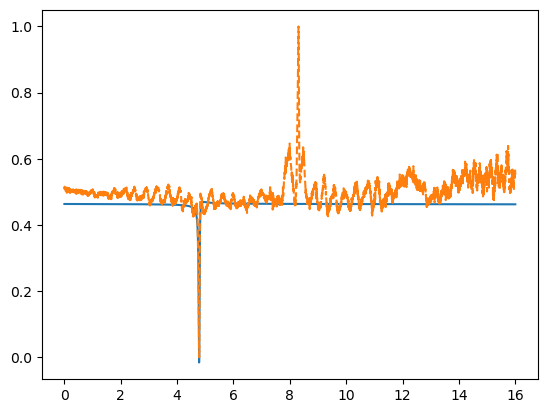

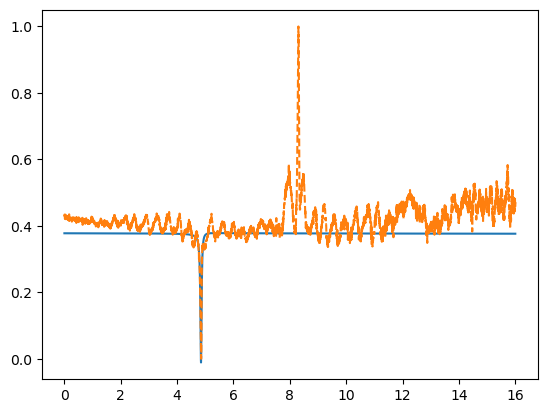

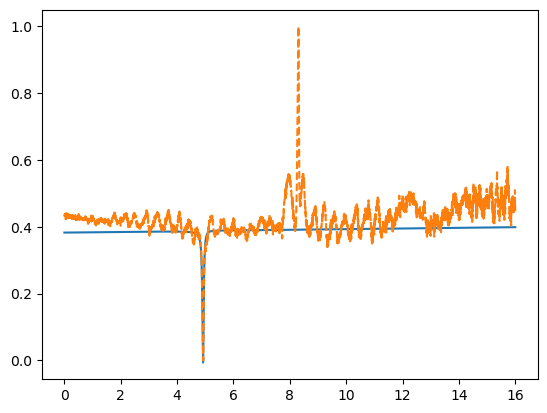

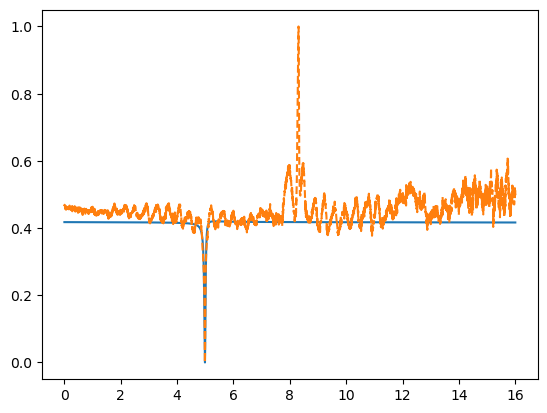

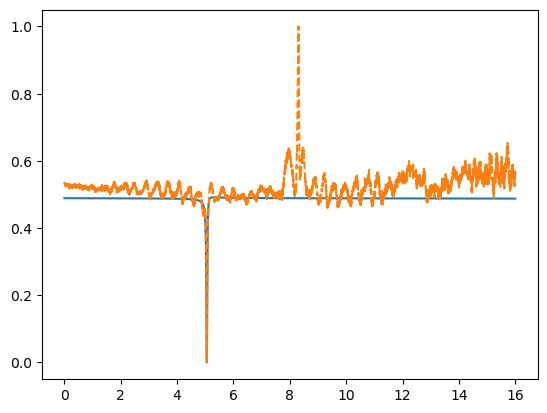

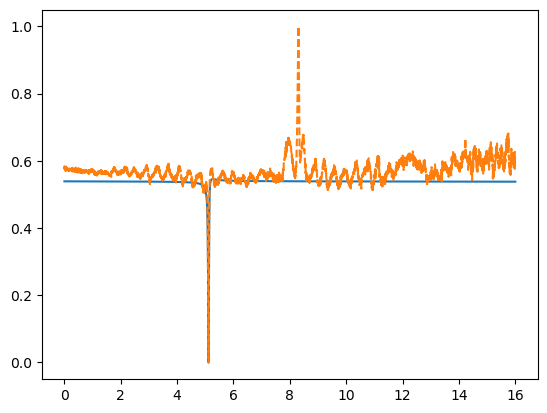

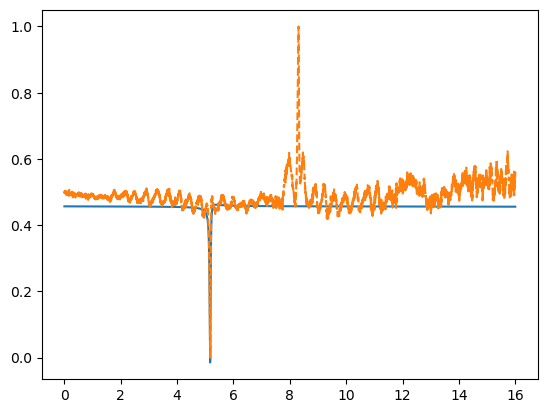

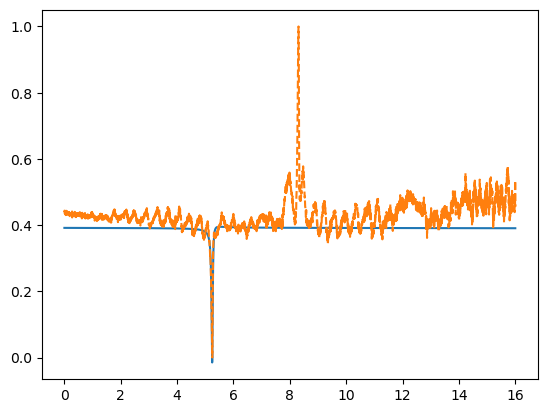

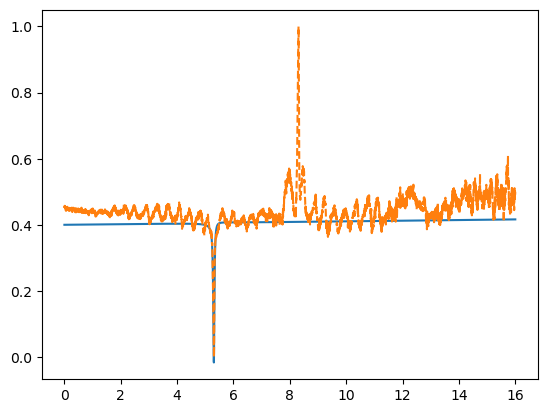

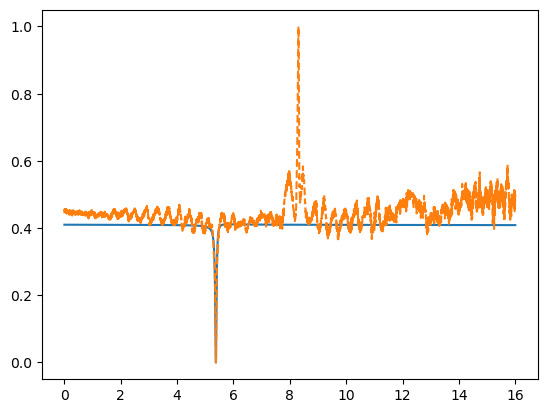

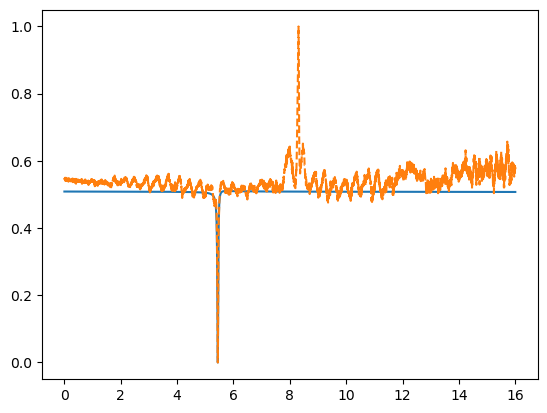

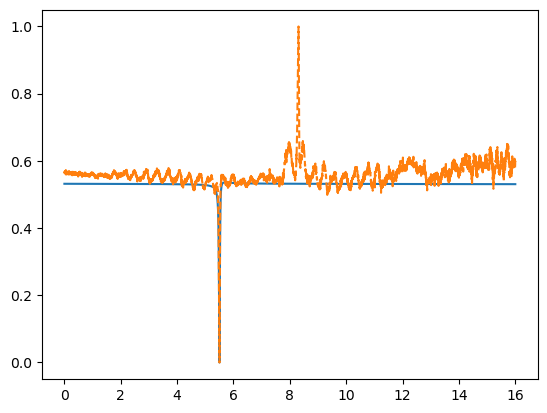

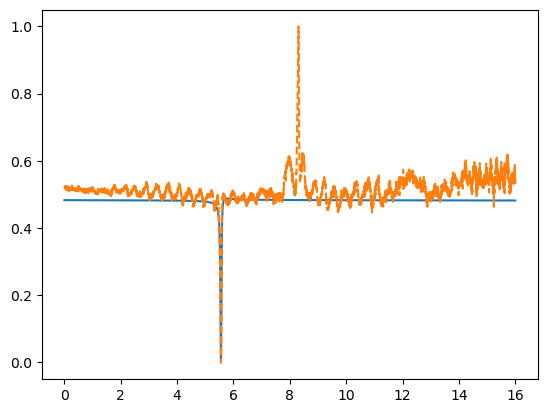

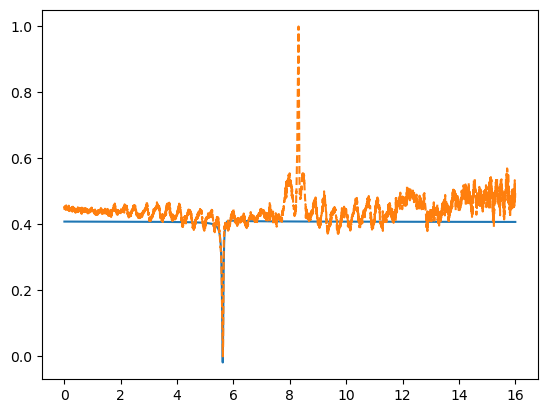

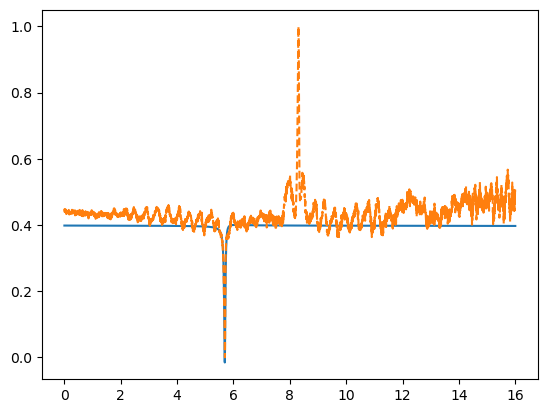

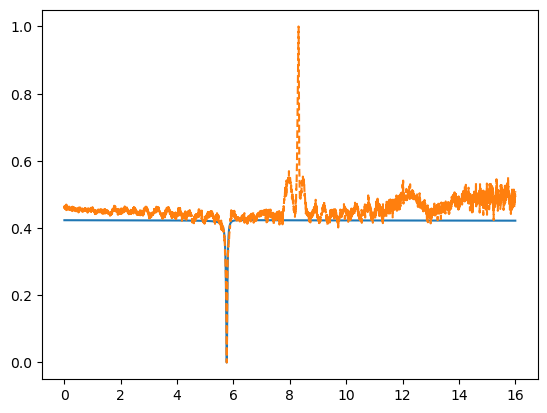

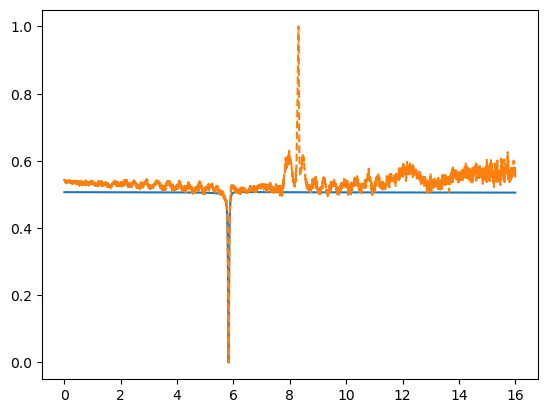

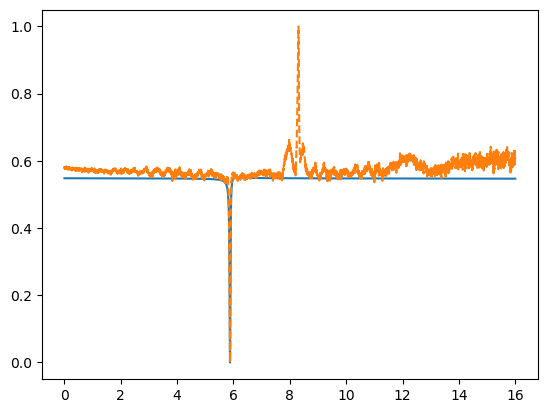

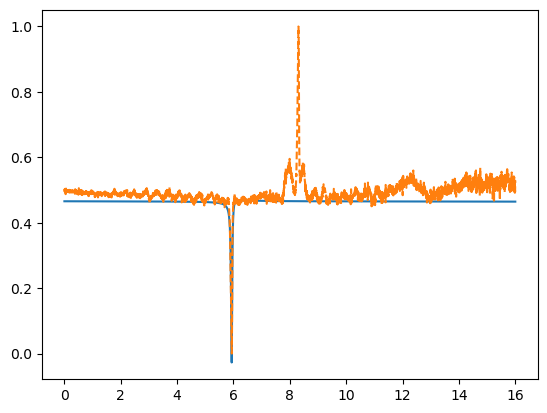

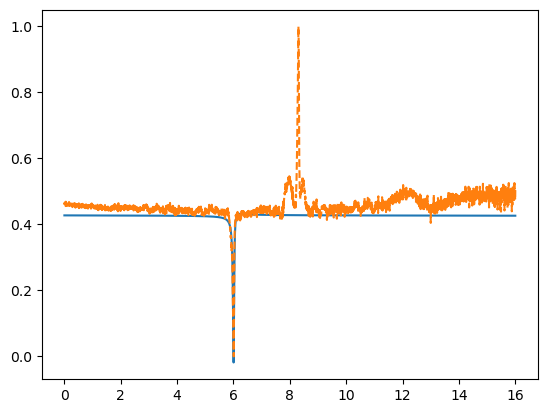

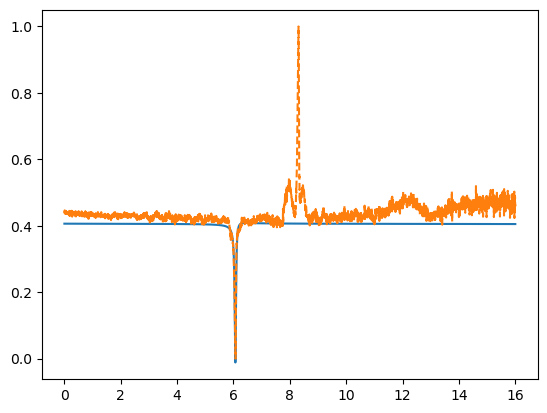

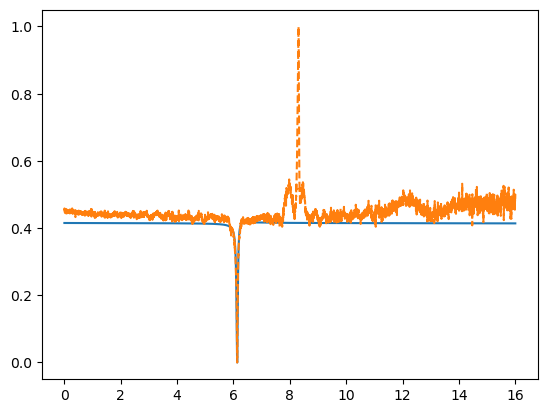

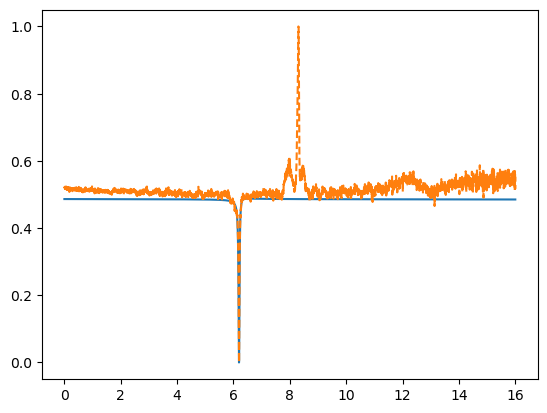

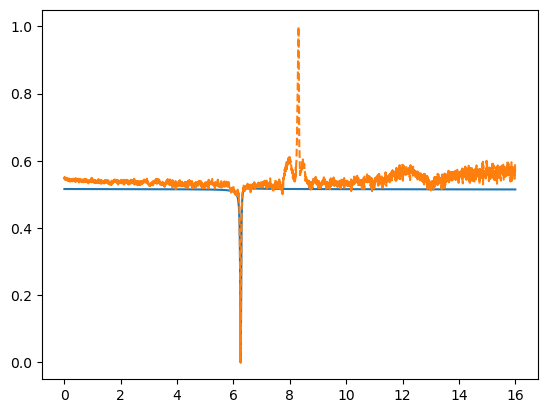

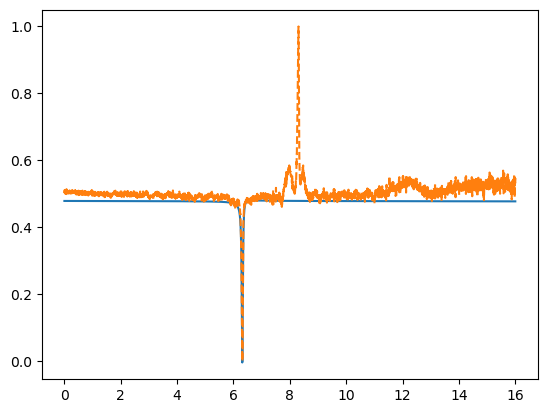

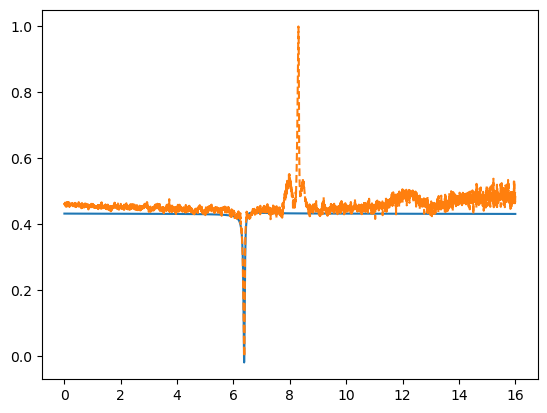

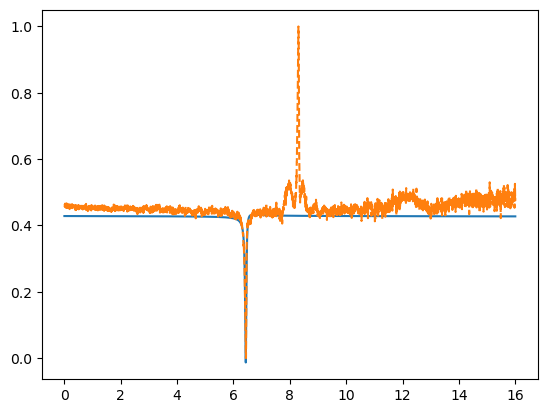

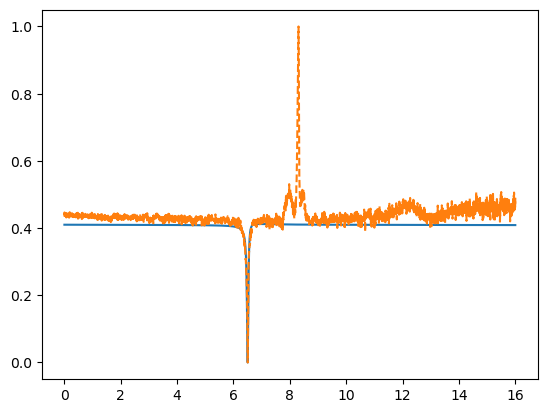

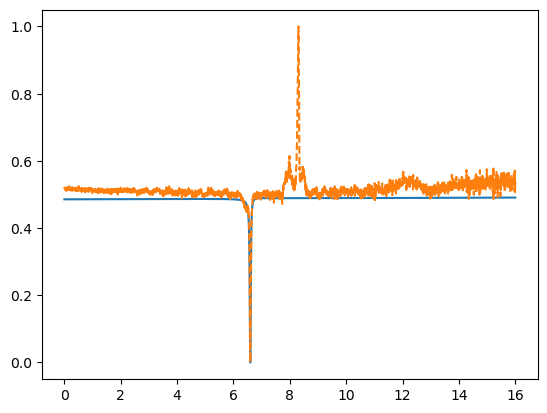

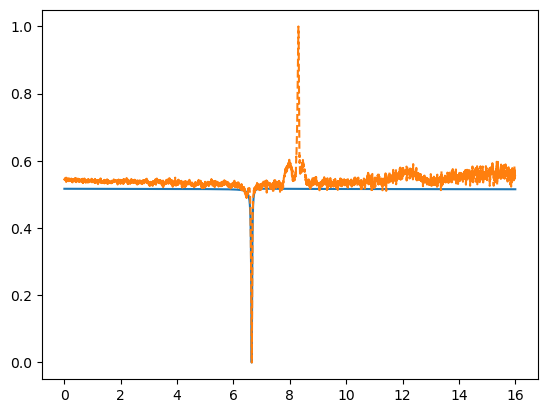

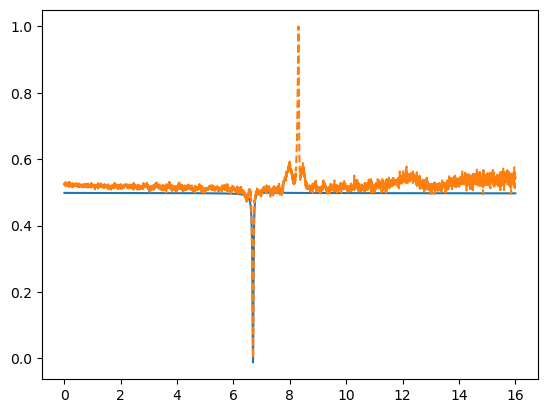

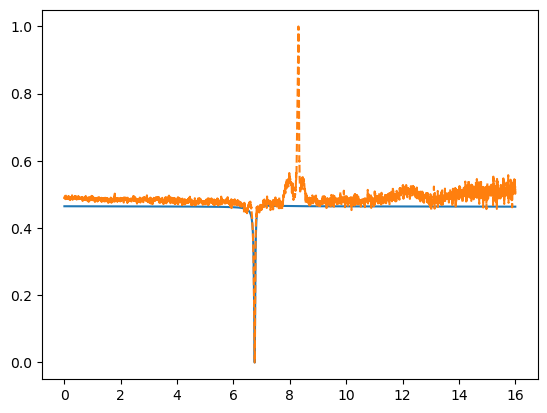

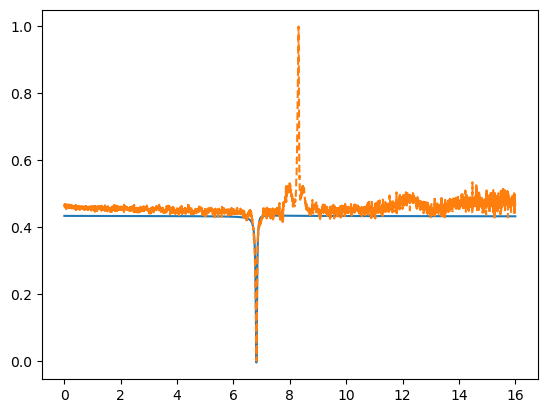

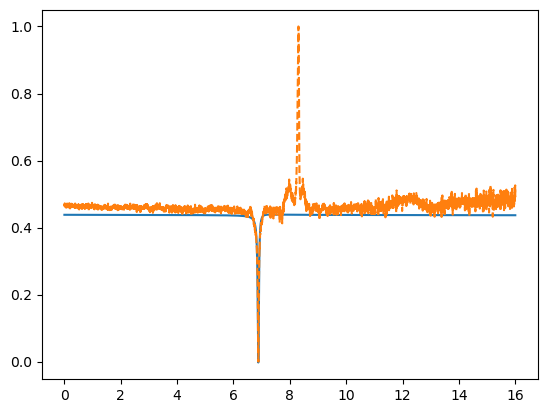

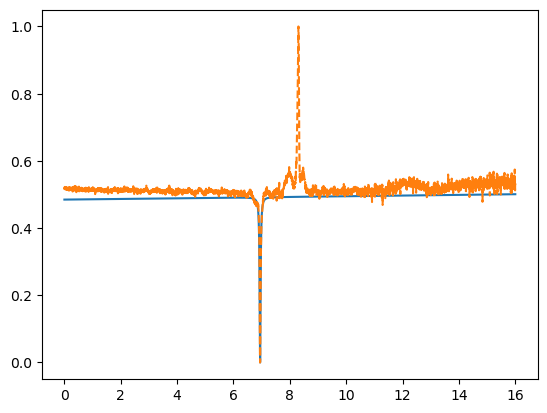

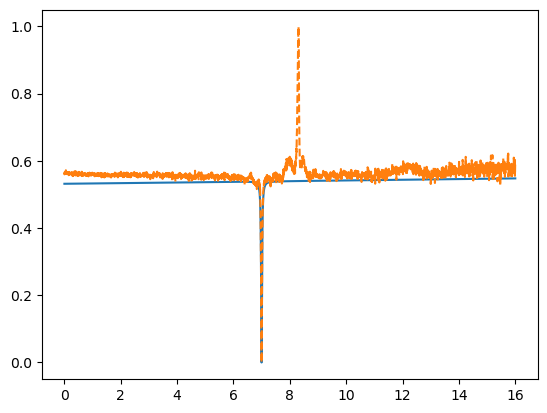

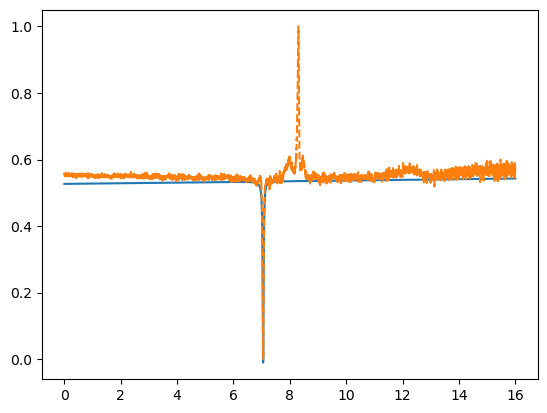

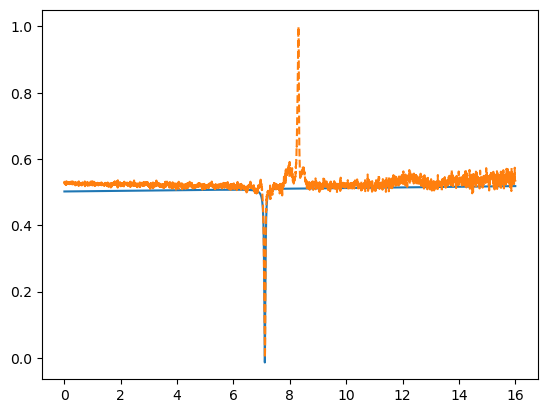

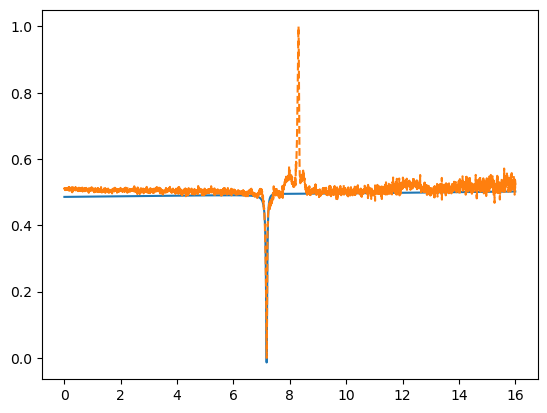

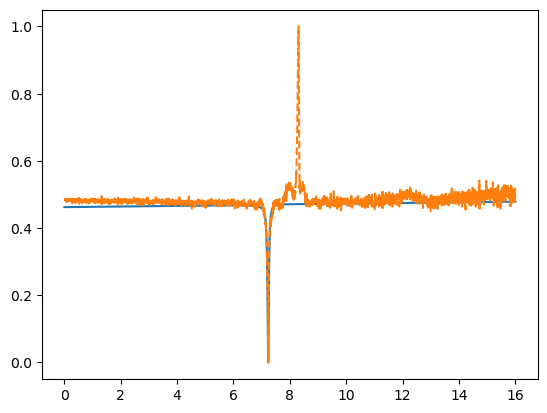

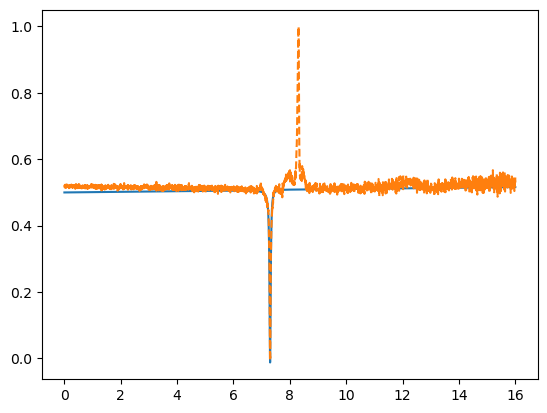

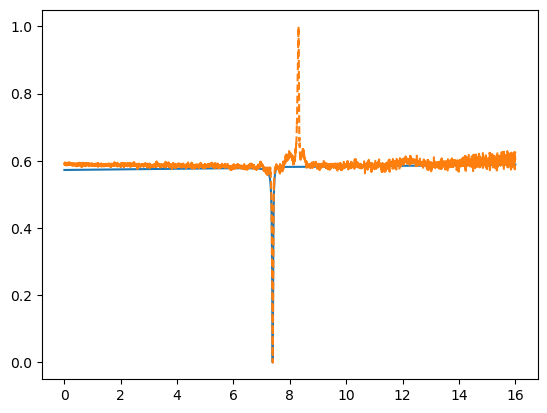

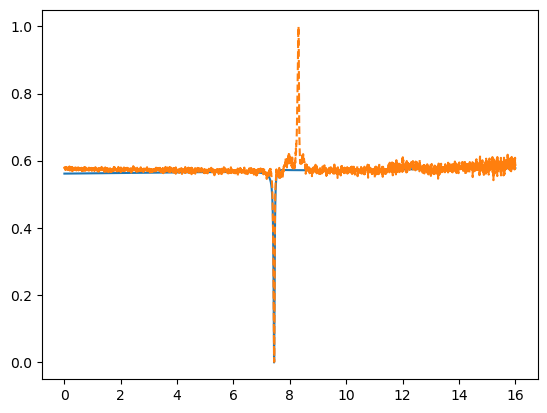

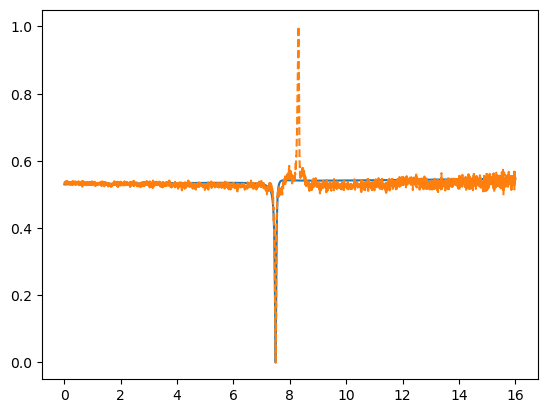

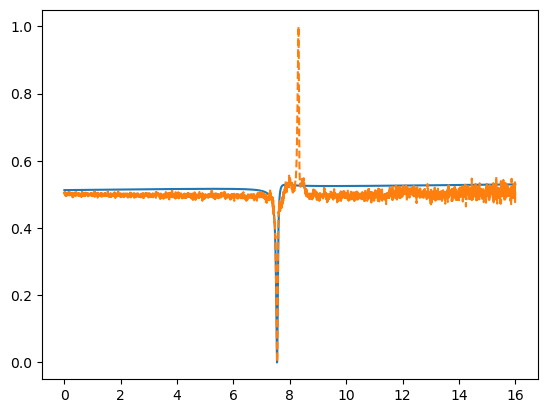

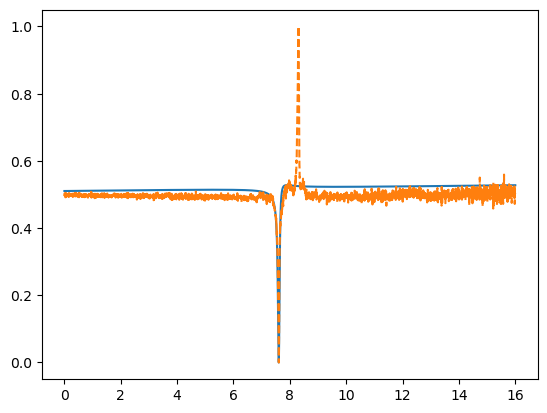

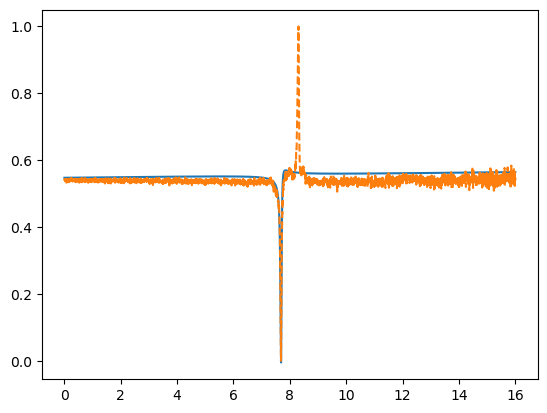

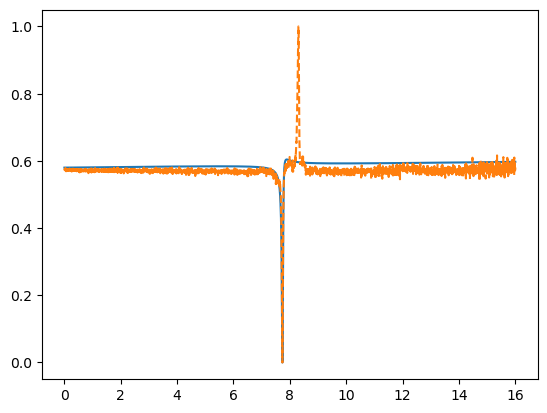

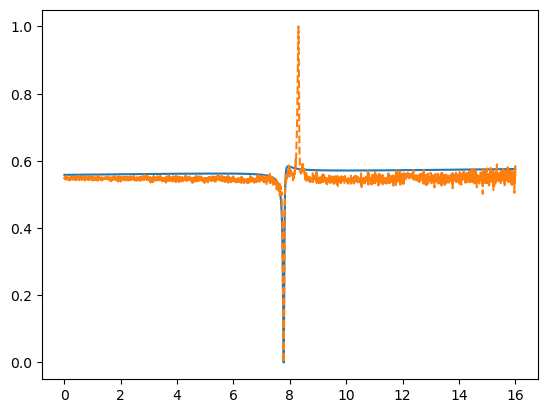

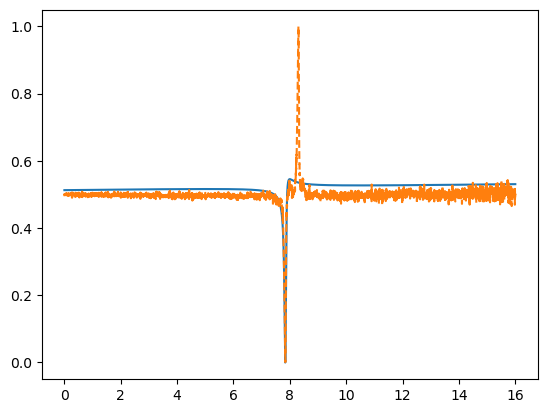

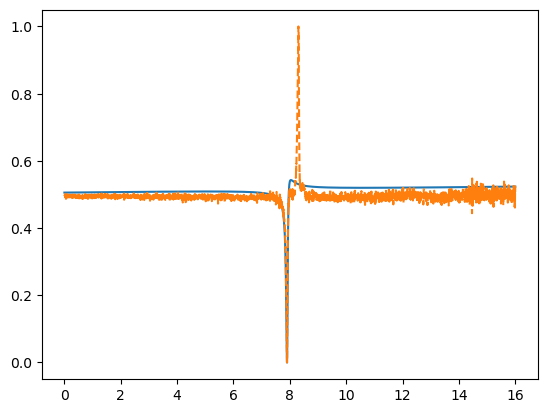

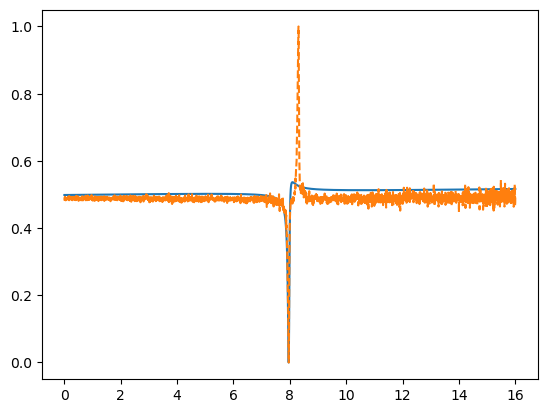

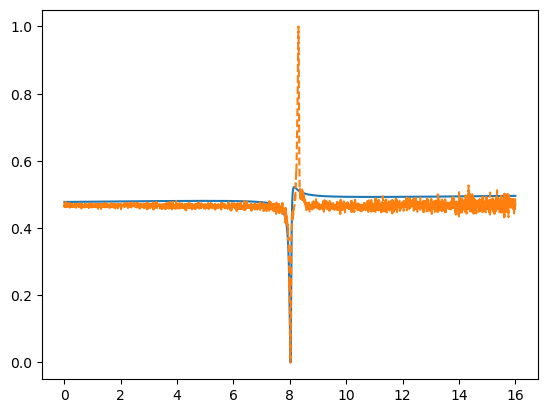

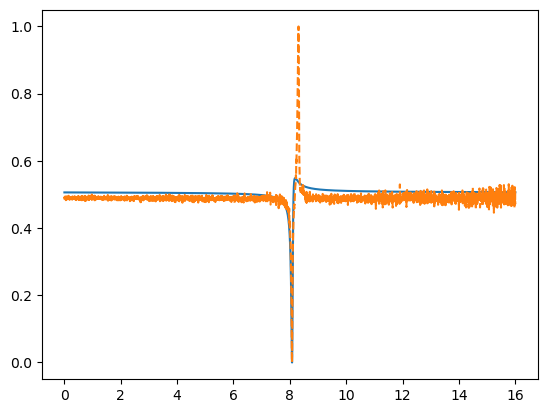

In [142]:

normalised_df = df.copy()

normalised_df = (normalised_df - normalised_df.min()) / (normalised_df.max() - normalised_df.min())

for column in df_lorentz_yig.columns:
    fig, ax = plt.subplots()

    ax.plot(df_lorentz_yig.index.values/1e9, df_lorentz_yig[column].values, label=f"B={column:.2f} mT")
    ax.plot(normalised_df.index.values/1e9, normalised_df[column].values, label=f"Data B={column:.2f} mT", linestyle='dashed')

Fitted gamma: 2.70e+01 ± 2.50e-01 GHz/T
Fitted M_eff: 198.10 ± 5.60 kA/m


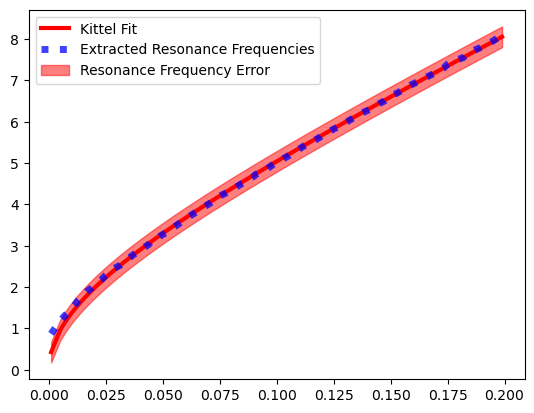

In [246]:
kittel_fit, kittel_popt, kittel_perr = yig_loader.kittel_fit()

fig, ax = plt.subplots()

ax.plot(yig_loader.kittel_raw['B_field'].values, kittel_fit/1e9, 'r-', label='Kittel Fit', linewidth = 3)
# ax.errorbar(yig_loader.kittel_raw['B_field'].values, kittel_fit/1e9, yerr=kittel_perr[0]/1e9, fmt='r-', capsize = 2, ecolor = "black",  elinewidth = 2,  label='Kittel Fit with Error Bars')

ax.plot(yig_loader.kittel_raw['B_field'].values, yig_loader.kittel_raw['center'].values/1e9, color='blue', ls=':' , linewidth = 5,alpha = 0.75,label='Extracted Resonance Frequencies')

ax.fill_between(yig_loader.kittel_raw['B_field'].values, (kittel_fit - kittel_perr[0])/1e9, (kittel_fit + kittel_perr[0])/1e9, color='red', alpha=0.5, label='Resonance Frequency Error')

ax.legend()


Fitted gamma: 2.70e+01 ± 2.50e-01 GHz/T
Fitted M_eff: 198.10 ± 5.60 kA/m


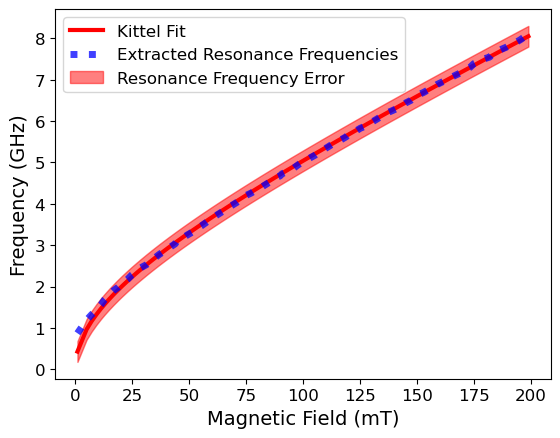

In [247]:
yig_loader.plot_kittel_fit(*yig_loader.kittel_fit())